# pair_split plotting scratchpad — 2018

A minimal starting point for interactive validation. It defines the measured
variables, bin edges, axis labels, and empty `hist.Hist` objects for:

- dijet: jet 1 and jet 2;
- trijet: jet 3.

There is one real example plot at the end: dijet jet-1 $p_T$. Add/fill the
other histograms as needed.

---

## What is in this notebook

| section | content | input |
|---|---|---|
| scaffold | variables, binning, empty `hist.Hist` placeholders, one example figure | pair_split skims |
| 1 | per-jet kinematics data/MC: $p_T$, $\eta$, $\phi$, $m_{\mathrm{SD}}$, ungroomed mass | pair_split skims |
| 2 | $\log(\rho^2)$ per measured-jet $p_T$ bin, with the systematic envelope | `minimal_rho` all_syst |
| 3 | $m_{\mathrm{SD}}$, $p_T$-inclusive, with the systematic envelope | `minimal_rho` all_syst |
| 4 | boundary distance $D$ of the leading dijet pair | pair_split skims |

The skim tables were produced with the `no_syst` profile, so sections 1 and 4
carry MC **statistical** bands only. The `minimal_rho` production has 77
systematic categories but no skim tables, hence the split.

## How to change things

Every cell keeps its knobs in a labelled block at the very top, with a comment
saying what changing each one does. Three concrete examples:

* **Normalize $\rho$ over a smaller window.** In any *Fig 2.x* cell,
  `rho_normalization_range = (-6.0, 0.0)`. Set it to e.g. `(-4.0, -1.0)` and
  the MC is rescaled to the data using only the sums *inside* that window --
  and the grey band is renormalized in exactly the same way.
* **Change a bin edge.** The mass binning is `BIN_EDGES["mass"]` in the
  *Variables and binning* cell (`np.linspace(0., 250., 51)`). Edit it, re-run
  that cell, then re-run the section-1 fill cell with `FORCE_RECOMPUTE = True`
  (or delete its cache file), then the figure cell.
* **Switch shape vs absolute.** Every *Fig 1.x* and *Fig 4.x* cell has
  `normalization = "shape"`; set it to `"absolute"` to compare raw weighted
  yields instead of unit-area shapes.

## A note on the ratio error bars

`hist`'s `plot_ratio` computes its ratio uncertainty assuming the numerator is
a raw Poisson count, and it draws the ratio points at the **left** bin edge.
The data here carries trigger-prescale weights (mean weight $\approx 2.6\times
10^{5}$ in the 200-290 GeV bin), so those bars would be a few hundred times too
small. Every figure cell therefore removes `plot_ratio`'s ratio points with a
single `.remove()` and redraws them at the bin centres with the properly
weighted error $\sqrt{\sum w^2}\,/\,\mathrm{MC}$. Everything else -- the main
panel, the two-panel layout, the legend -- is still `plot_ratio`.

## The little triangles at the axis edges

Those are `mplhep`'s *flow hint*: the histogram has entries in its underflow or
overflow bin, i.e. outside the drawn range (jets with $|\eta| > 2.5$,
$p_T > 1500$ GeV, $m_{\mathrm{SD}} > 250$ GeV, ...). They are drawn
automatically by `histplot` and are information, not a drawing bug.

## Weights

**Never re-apply a cross section.** The skim `weight` column and the stored
histograms are ALREADY scaled by `xs*lumi*1000/sumw` for MC; for data `weight`
is the trigger prescale weight. See the module docstring of
`scripts/validate_pairsplit.py`. The batch/deck version of these same figures
is `python scripts/validate_pairsplit.py all --outdir DIR`.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import hist
import matplotlib.pyplot as plt
import mplhep as hep
import numpy as np

# Change this path only if you move the repository.
REPO = Path("/Users/aritra/Projects/smp_jetmass_run2")
if not (REPO / "scripts" / "validate_pairsplit.py").is_file():
    raise RuntimeError(f"Cannot find the repository at {REPO}; update REPO in this cell.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from scripts import validate_pairsplit as vp

hep.style.use(hep.style.CMS)
ERA = "2018"
LUMI = "59.8 fb$^{-1}$ (13 TeV)"

# Use the pair_split skim pickles for this era.
for channel in ("dijet", "trijet"):
    for source in ("mc", "data"):
        vp.INPUTS[("new", channel, source)] = (
            f"{vp.NEW_ROOT}/{ERA}/{channel}_{source}", "*.pkl"
        )

print("kernel:", sys.executable)

kernel: /Users/aritra/Projects/GluonJetMass/.venv/bin/python


## Variables and binning

Definitions:

- `pt`: measured-jet $p_T$;
- `eta`, `phi`: measured-jet coordinates;
- `mass`: groomed mass, $m_{\mathrm{SD}}$;
- `rho`: $2\log_{10}[m_{\mathrm{SD}}/(p_T\,0.8)]$;
- `D`: leading dijet-pair distance to the pair-split boundary,
  $\Delta\phi_{12} - [\pi - 200\,\mathrm{GeV}/\bar p_T]$.

In [2]:
# Analysis pT bin edges: keep these exactly as used by the processors.
PT_EDGES = {
    "dijet": np.array([200., 290., 400., 480., 570., 680., 760., 820., 1500.]),
    "trijet": np.array([185., 200., 290., 400., 1500.]),
}

# Convenient plotting bin edges for the other variables.
BIN_EDGES = {
    "pt": PT_EDGES["dijet"],       # use PT_EDGES[channel] when filling
    "eta": np.linspace(-2.5, 2.5, 51),
    "phi": np.linspace(-np.pi, np.pi, 65),
    "mass": np.linspace(0., 250., 51),
    "rho": np.linspace(-6., 0., 49),
    "D": np.linspace(0., 1.6, 65),
}

AXIS_LABELS = {
    "pt": r"jet $p_T$ [GeV]",
    "eta": r"jet $\eta$",
    "phi": r"jet $\phi$",
    "mass": r"jet $m_{\mathrm{SD}}$ [GeV]",
    "rho": r"$\log(\rho^2)$",
    "D": r"$D = \Delta\phi_{12} - (\pi - 200\,\mathrm{GeV}/\bar p_T)$",
}

# Variable names expected in the pair_split reco skim tables.
VARIABLES = ("pt", "eta", "phi", "mass", "rho", "D")
JETS = {"dijet": ("jet1", "jet2"), "trijet": ("jet3",)}

for channel, edges in PT_EDGES.items():
    print(f"{channel:6s} pT edges: {edges}")

dijet  pT edges: [ 200.  290.  400.  480.  570.  680.  760.  820. 1500.]
trijet pT edges: [ 185.  200.  290.  400. 1500.]


## Empty `hist.Hist` placeholders

Every histogram has a `source` axis (`mc` / `data`) and a weighted storage.
They are empty until you call `.fill(...)`. `D` is only defined for the dijet
leading pair, so it has one placeholder: `hists["dijet_pair_D"]`.

In [3]:
source_axis = hist.axis.StrCategory([], growth=True, name="source", label="source")


def make_hist(variable, channel=None):
    """Create one weighted histogram with its readable axis label."""
    edges = PT_EDGES[channel] if variable == "pt" and channel else BIN_EDGES[variable]
    variable_axis = hist.axis.Variable(edges, name=variable, label=AXIS_LABELS[variable])
    return hist.Hist(source_axis, variable_axis, storage=hist.storage.Weight())


# Fill any of these later, for example:
# hists["dijet_jet2_mass"].fill(source="data", mass=my_msd, weight=my_weight)
hists = {
    f"{channel}_{jet}_{variable}": make_hist(variable, channel)
    for channel, jets in JETS.items()
    for jet in jets
    for variable in ("pt", "eta", "phi", "mass", "rho")
}
hists["dijet_pair_D"] = make_hist("D")

print("empty histograms:")
print(*hists, sep="\n")

empty histograms:
dijet_jet1_pt
dijet_jet1_eta
dijet_jet1_phi
dijet_jet1_mass
dijet_jet1_rho
dijet_jet2_pt
dijet_jet2_eta
dijet_jet2_phi
dijet_jet2_mass
dijet_jet2_rho
trijet_jet3_pt
trijet_jet3_eta
trijet_jet3_phi
trijet_jet3_mass
trijet_jet3_rho
dijet_pair_D


## One example: dijet jet-1 $p_T$

This shows the shortest useful filling pattern. The reco skim stores all jets as
rows; `jetidx == 0` selects the leading measured jet. The stored weights already
contain the appropriate MC normalization or data trigger prescale.

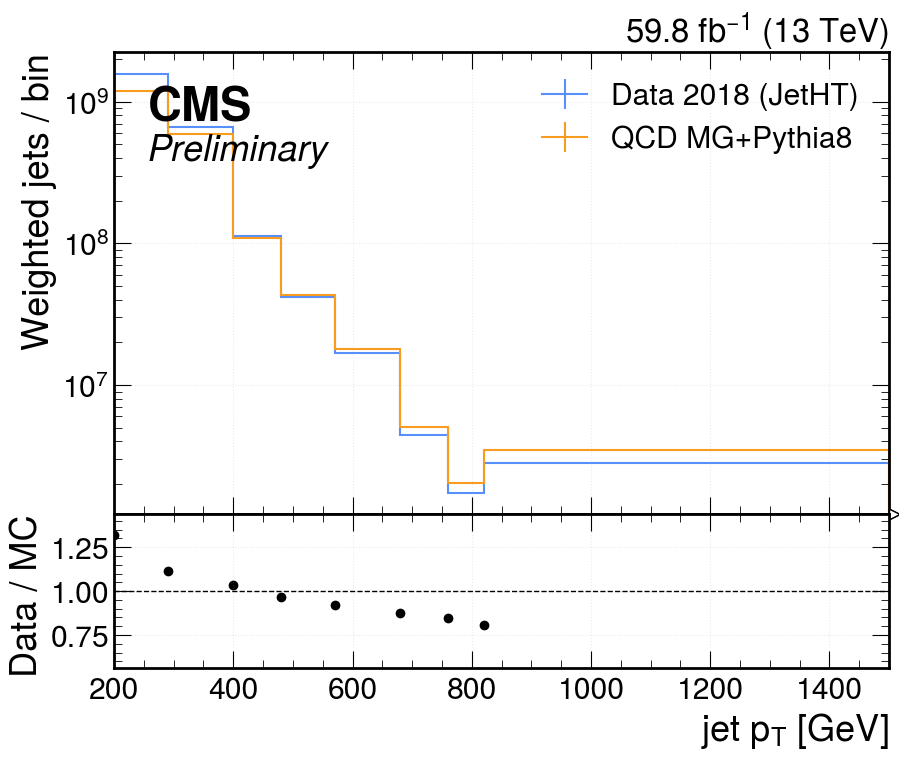

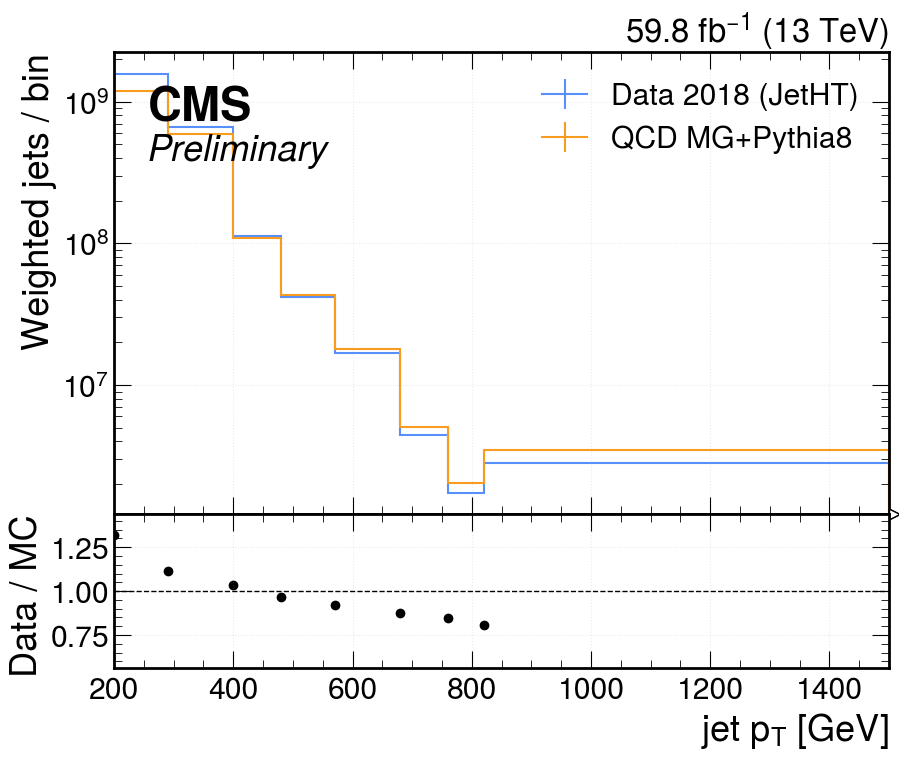

In [4]:
h_pt = hists["dijet_jet1_pt"]

for source in ("mc", "data"):
    for _, table in vp.stream_table("new", "dijet", source, "reco",
                                    ("ptreco", "jetidx", "weight"), quiet=True):
        leading_jet = table["jetidx"] == 0
        h_pt.fill(
            source=source,
            pt=table["ptreco"][leading_jet],
            weight=table["weight"][leading_jet],
        )

# hist.plot_ratio makes the main data/MC plot and the ratio panel together.
# The selections remove the categorical `source` axis, leaving a 1D pT histogram.
hist_data = h_pt[{"source": "data"}]
hist_mc = h_pt[{"source": "mc"}]

fig = plt.figure(figsize=(10, 8))
main_ax_artists, subplot_ax_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label="Data 2018 (JetHT)",
    rp_denom_label="QCD MG+Pythia8",
    rp_uncert_draw_type="bar",
)

# plot_ratio returns artists; use the two figure axes for the final styling.
main_ax, ratio_ax = fig.axes
main_ax.set_yscale("log")
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(PT_EDGES["dijet"][0], PT_EDGES["dijet"][-1])
main_ax.grid(alpha=0.25)
ratio_ax.set_xlabel(AXIS_LABELS["pt"])
ratio_ax.grid(alpha=0.25)
hep.cms.label("Preliminary", data=True, loc=2, ax=main_ax, rlabel=LUMI)
fig

## Cache and the recompute switch

Filling the histograms below streams several million skim rows. Each *fill*
cell writes its finished `hist.Hist` objects to
`notebooks/.cache_pairsplit_2018/` with `pickle` and reloads them on the next
run. Set `FORCE_RECOMPUTE = True` (or delete the file named in the cell) after
changing a binning, a column, or the selection.

In [5]:
import pickle

from matplotlib.ticker import MaxNLocator

# Where the filled histograms are cached. One .pkl per fill cell.
CACHE_DIR = REPO / "notebooks" / ".cache_pairsplit_2018"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Set True to ignore every cache file and refill from the inputs. Leave False
# for normal plotting work; flip it after changing a binning or a column.
FORCE_RECOMPUTE = False

# Legend labels, used verbatim by every figure below.
DATA_LABEL = "Data 2018 (JetHT)"
MC_LABEL = "QCD MG+Pythia8"

print("cache dir:", CACHE_DIR)
print("FORCE_RECOMPUTE =", FORCE_RECOMPUTE)
for existing in sorted(CACHE_DIR.glob("*.pkl")):
    print(f"  {existing.name:<28s} {existing.stat().st_size / 1e6:6.1f} MB")

cache dir: /Users/aritra/Projects/smp_jetmass_run2/notebooks/.cache_pairsplit_2018
FORCE_RECOMPUTE = False
  boundary_hists.pkl              0.0 MB
  kinematics_hists.pkl            0.0 MB
  msd_variations.pkl              0.1 MB
  rho_variations.pkl              0.6 MB


## 1. Per-jet kinematics, data vs MC

The measured jets are the two leading AK8 jets in the dijet channel
(`jetidx` 0 and 1) and the third jet in the trijet channel (`jetidx` 2). For
each of them we compare data and MC in $p_T$, $\eta$, $\phi$, the groomed mass
$m_{\mathrm{SD}}$ (skim column `mreco_g`) and the ungroomed mass (skim column
`mreco_u`).

In [6]:
# ---- knobs -------------------------------------------------------------
cache_file = CACHE_DIR / "kinematics_hists.pkl"

# The scaffold has no placeholder for the UNGROOMED jet mass, so register its
# binning and label here; `make_hist` then treats it like any other variable.
# Change the linspace to change the ungroomed-mass axis.
BIN_EDGES["mass_ungroomed"] = np.linspace(0., 300., 61)
AXIS_LABELS["mass_ungroomed"] = r"jet $m_{\mathrm{ungroomed}}$ [GeV]"

# Which skim column feeds which histogram axis. `rho` is derived below.
COLUMN_FOR = {
    "pt": "ptreco",
    "eta": "etareco",
    "phi": "phireco",
    "mass": "mreco_g",            # groomed = soft-drop mass
    "mass_ungroomed": "mreco_u",  # ungroomed AK8 mass
}
KINEMATIC_VARIABLES = tuple(COLUMN_FOR) + ("rho",)

# jetidx of each measured jet, as written by HadronicProcessorBase._fill_skim.
JET_INDEX = {"dijet": {"jet1": 0, "jet2": 1}, "trijet": {"jet3": 2}}

JET_RADIUS = 0.8   # AK8; rho = 2*log10(m_SD / (pt * R))
# ------------------------------------------------------------------------

if cache_file.exists() and not FORCE_RECOMPUTE:
    hists = pickle.load(open(cache_file, "rb"))
    print("loaded", cache_file.name)
else:
    # Rebuild the placeholders from scratch. The example cell above already put
    # the dijet jet-1 pT entries into hists["dijet_jet1_pt"], and filling that
    # same object again would double-count it.
    hists = {
        f"{channel}_{jet}_{variable}": make_hist(variable, channel)
        for channel, jets in JETS.items()
        for jet in jets
        for variable in KINEMATIC_VARIABLES
    }
    hists["dijet_pair_D"] = make_hist("D")

    for channel in ("dijet", "trijet"):
        for source in ("mc", "data"):
            print(f"filling {channel} {source} ...")
            for _, table in vp.stream_table(
                    "new", channel, source, "reco",
                    tuple(COLUMN_FOR.values()) + ("jetidx", "weight"),
                    quiet=True):
                for jet, jetidx in JET_INDEX[channel].items():
                    rows = table["jetidx"] == jetidx
                    jet_weight = table["weight"][rows]
                    for variable, column in COLUMN_FOR.items():
                        hists[f"{channel}_{jet}_{variable}"].fill(
                            source, table[column][rows], weight=jet_weight)
                    # rho from the groomed mass; m_SD = 0 gives -inf, drop those
                    with np.errstate(divide="ignore", invalid="ignore"):
                        rho_values = 2.0 * np.log10(
                            table["mreco_g"][rows]
                            / (table["ptreco"][rows] * JET_RADIUS))
                    finite = np.isfinite(rho_values)
                    hists[f"{channel}_{jet}_rho"].fill(
                        source, rho_values[finite], weight=jet_weight[finite])

    pickle.dump(hists, open(cache_file, "wb"))
    print("wrote", cache_file.name)

for name, histogram in hists.items():
    if name.endswith("_D"):
        continue
    mc_sum = histogram[{"source": "mc"}].values().sum()
    data_sum = histogram[{"source": "data"}].values().sum()
    print(f"  {name:<28s} MC {mc_sum:11.5g}   data {data_sum:11.5g}")

loaded kinematics_hists.pkl
  dijet_jet1_pt                MC  1.9666e+09   data  2.4129e+09
  dijet_jet1_eta               MC  1.9666e+09   data  2.4129e+09
  dijet_jet1_phi               MC  1.9664e+09   data  2.4129e+09
  dijet_jet1_mass              MC  1.9603e+09   data  2.4058e+09
  dijet_jet1_mass_ungroomed    MC  1.9664e+09   data  2.4127e+09
  dijet_jet1_rho               MC  1.9559e+09   data  2.3984e+09
  dijet_jet2_pt                MC  1.9666e+09   data  2.4129e+09
  dijet_jet2_eta               MC  1.9666e+09   data  2.4129e+09
  dijet_jet2_phi               MC  1.9665e+09   data  2.4128e+09
  dijet_jet2_mass              MC  1.9644e+09   data  2.4102e+09
  dijet_jet2_mass_ungroomed    MC  1.9665e+09   data  2.4128e+09
  dijet_jet2_rho               MC   1.961e+09   data  2.4048e+09
  trijet_jet3_pt               MC  2.3532e+07   data  2.4319e+07
  trijet_jet3_eta              MC  2.3532e+07   data  2.4319e+07
  trijet_jet3_phi              MC   2.353e+07   data  2.4318e+

**Fig 1.1** &mdash; dijet, measured-jet $p_T$ (jets 1 + 2).

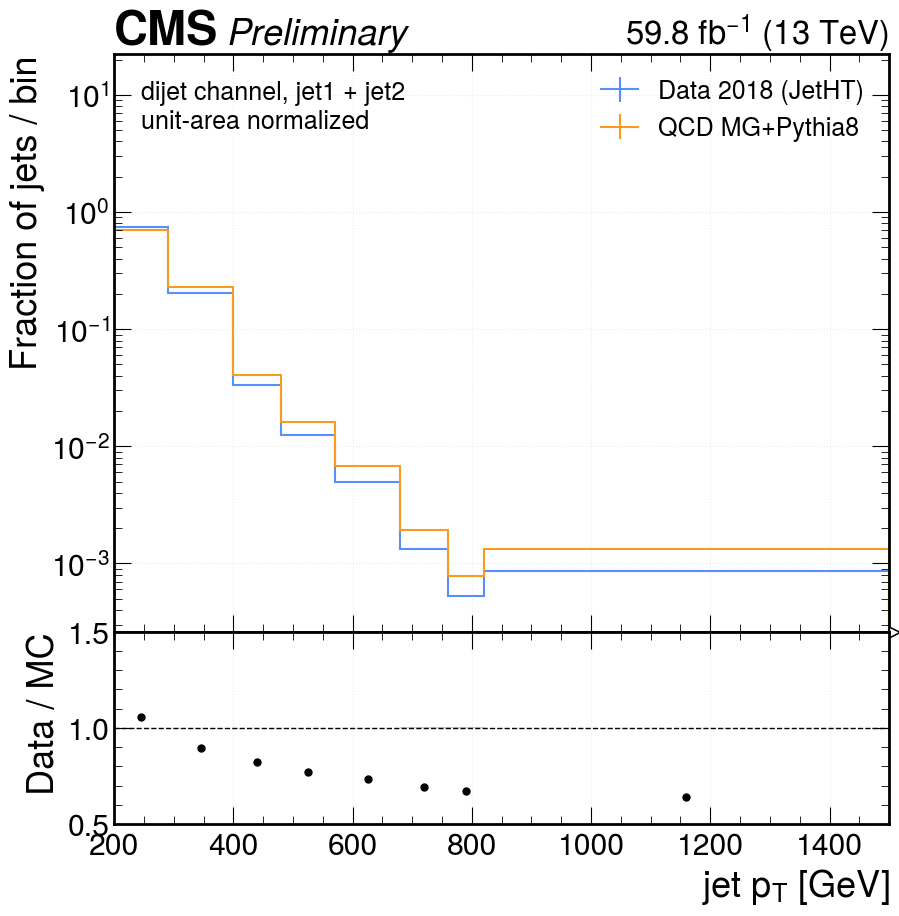

In [7]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
variable = "pt"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet1", "jet2"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (200., 1500.)          # x window that is drawn
ratio_y_range = (0.5, 1.5)      # y window of the Data / MC panel
log_y = True                    # log scale on the main panel
legend_headroom = 30      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.2** &mdash; dijet, measured-jet $\eta$ (jets 1 + 2).

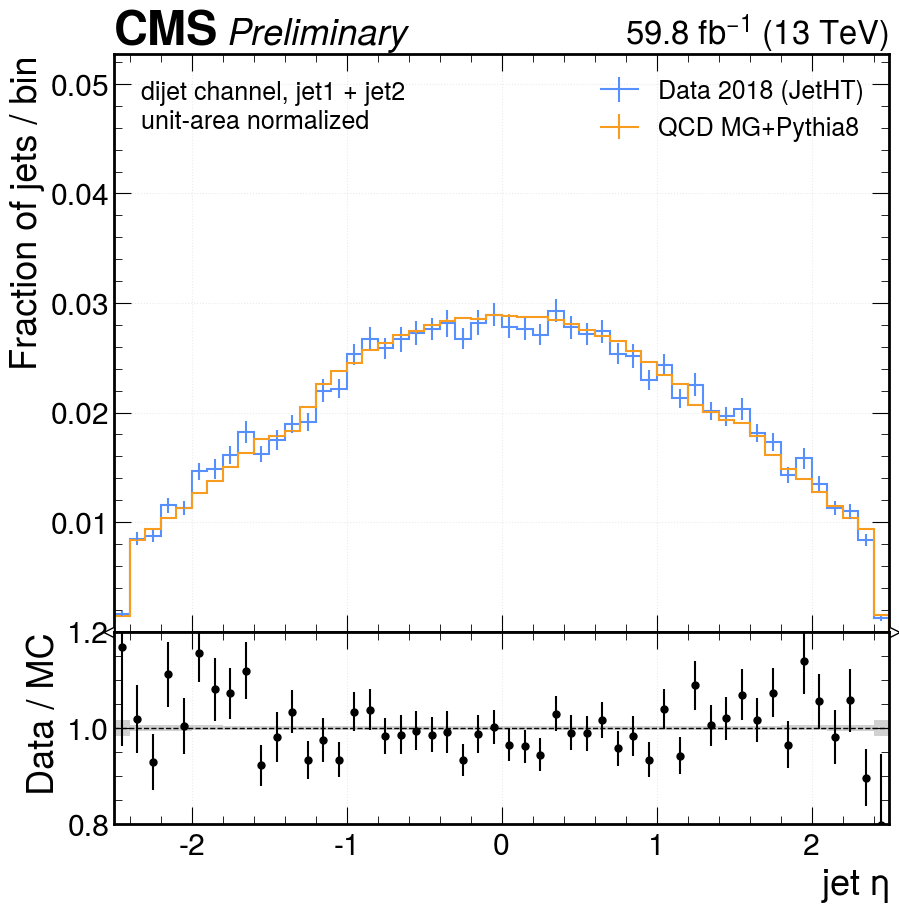

In [8]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
variable = "eta"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet1", "jet2"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (-2.5, 2.5)          # x window that is drawn
ratio_y_range = (0.8, 1.2)      # y window of the Data / MC panel
log_y = False                    # log scale on the main panel
legend_headroom = 1.8      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.3** &mdash; dijet, measured-jet $\phi$ (jets 1 + 2).

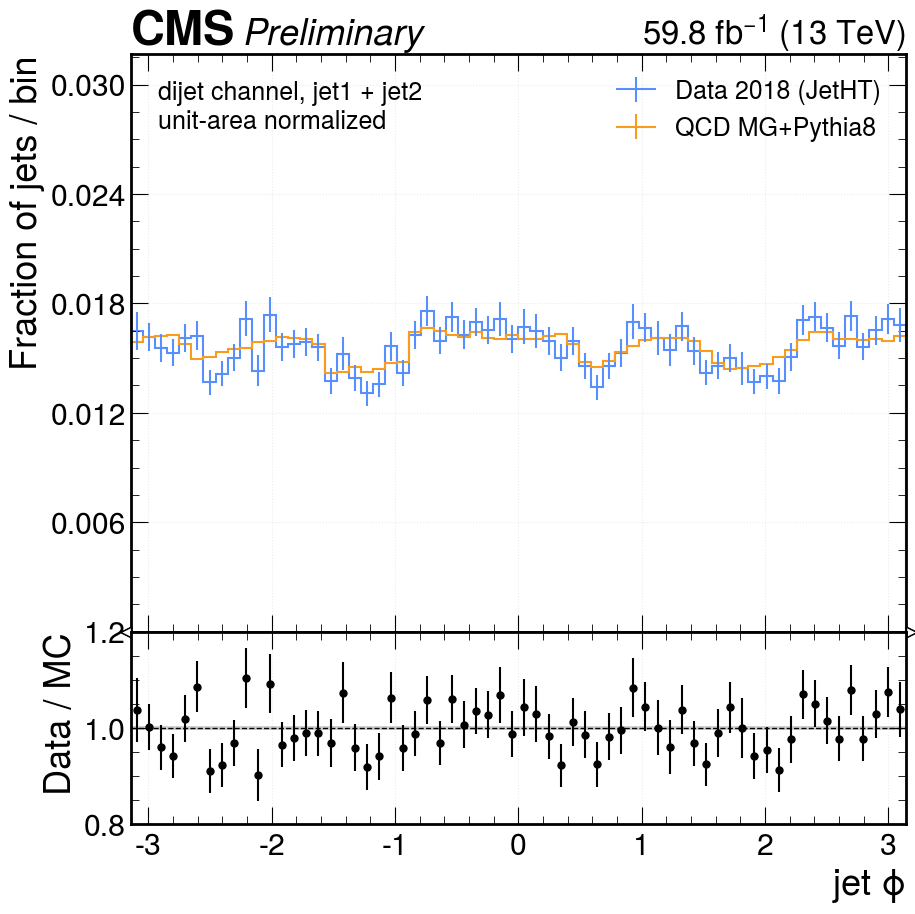

In [9]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
variable = "phi"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet1", "jet2"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (-np.pi, np.pi)          # x window that is drawn
ratio_y_range = (0.8, 1.2)      # y window of the Data / MC panel
log_y = False                    # log scale on the main panel
legend_headroom = 1.8      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.4** &mdash; dijet, groomed mass $m_{\mathrm{SD}}$ (jets 1 + 2).

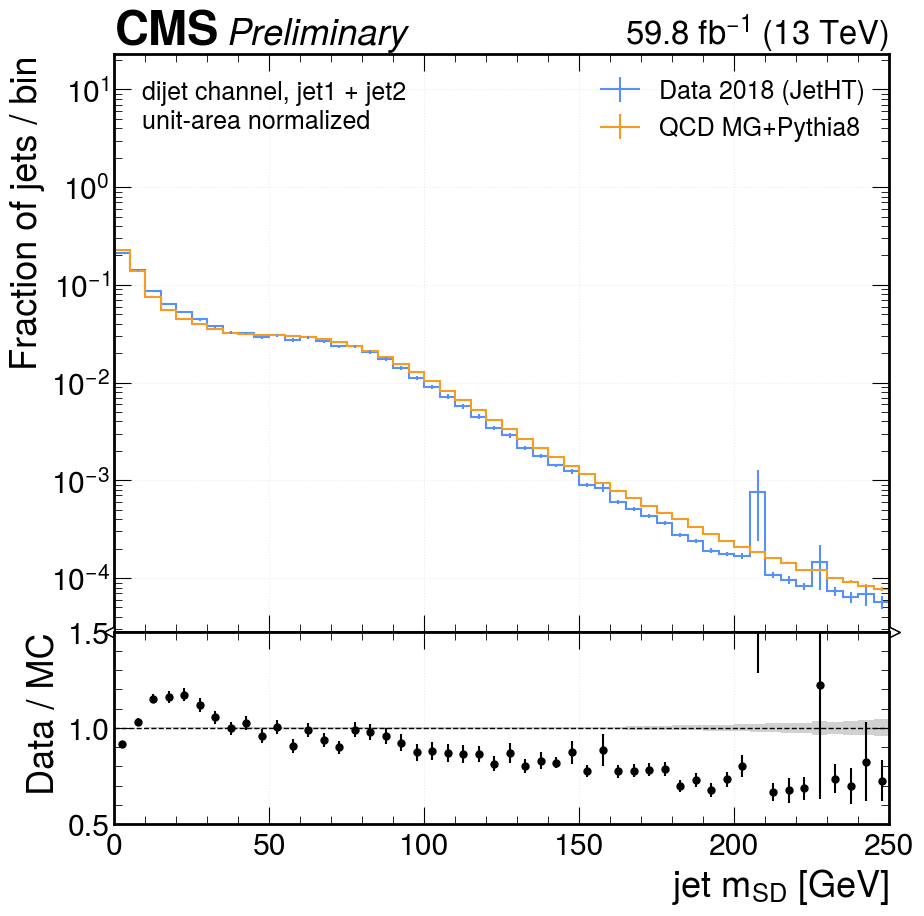

In [10]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
variable = "mass"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet1", "jet2"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (0., 250.)          # x window that is drawn
ratio_y_range = (0.5, 1.5)      # y window of the Data / MC panel
log_y = True                    # log scale on the main panel
legend_headroom = 100      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.5** &mdash; dijet, ungroomed mass (jets 1 + 2).

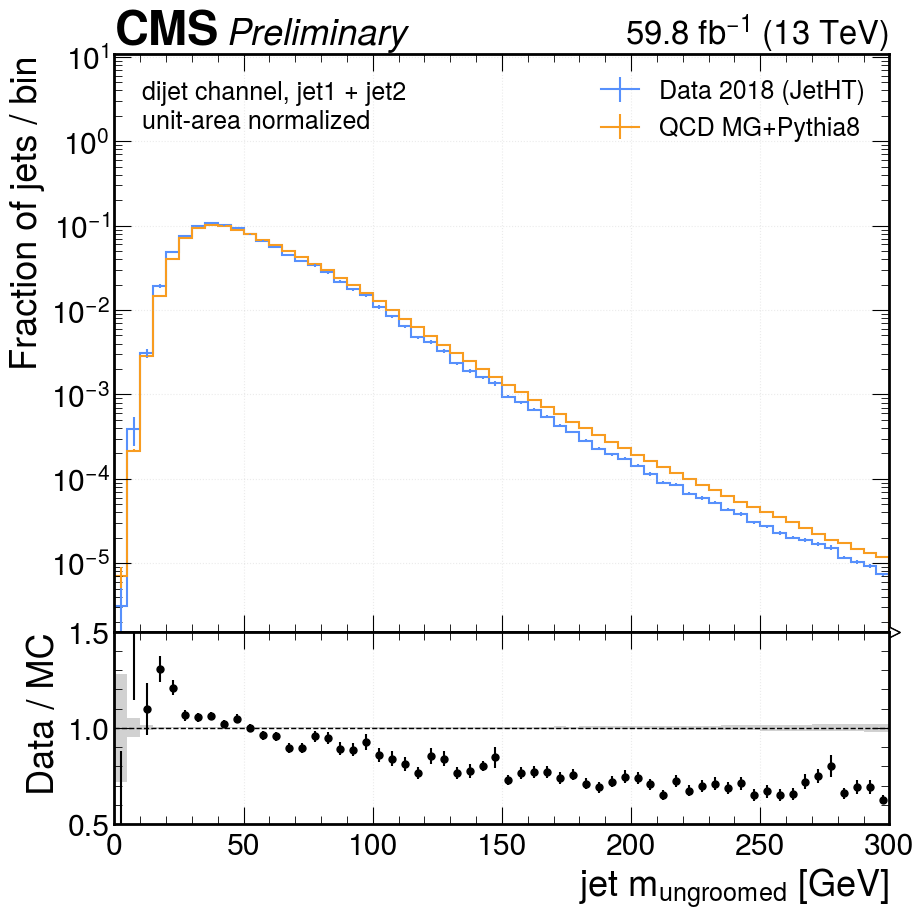

In [11]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
variable = "mass_ungroomed"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet1", "jet2"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (0., 300.)          # x window that is drawn
ratio_y_range = (0.5, 1.5)      # y window of the Data / MC panel
log_y = True                    # log scale on the main panel
legend_headroom = 100      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.6** &mdash; trijet, measured-jet $p_T$ (jet 3).

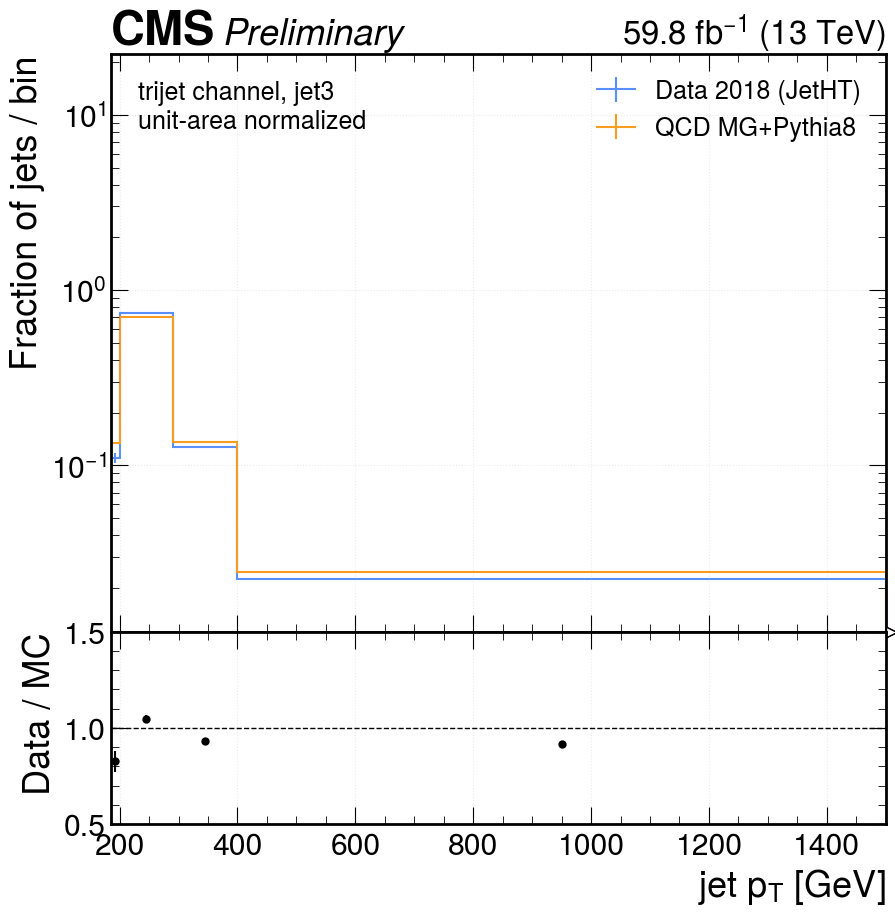

In [12]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
variable = "pt"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet3"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (185., 1500.)          # x window that is drawn
ratio_y_range = (0.5, 1.5)      # y window of the Data / MC panel
log_y = True                    # log scale on the main panel
legend_headroom = 30      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.7** &mdash; trijet, measured-jet $\eta$ (jet 3).

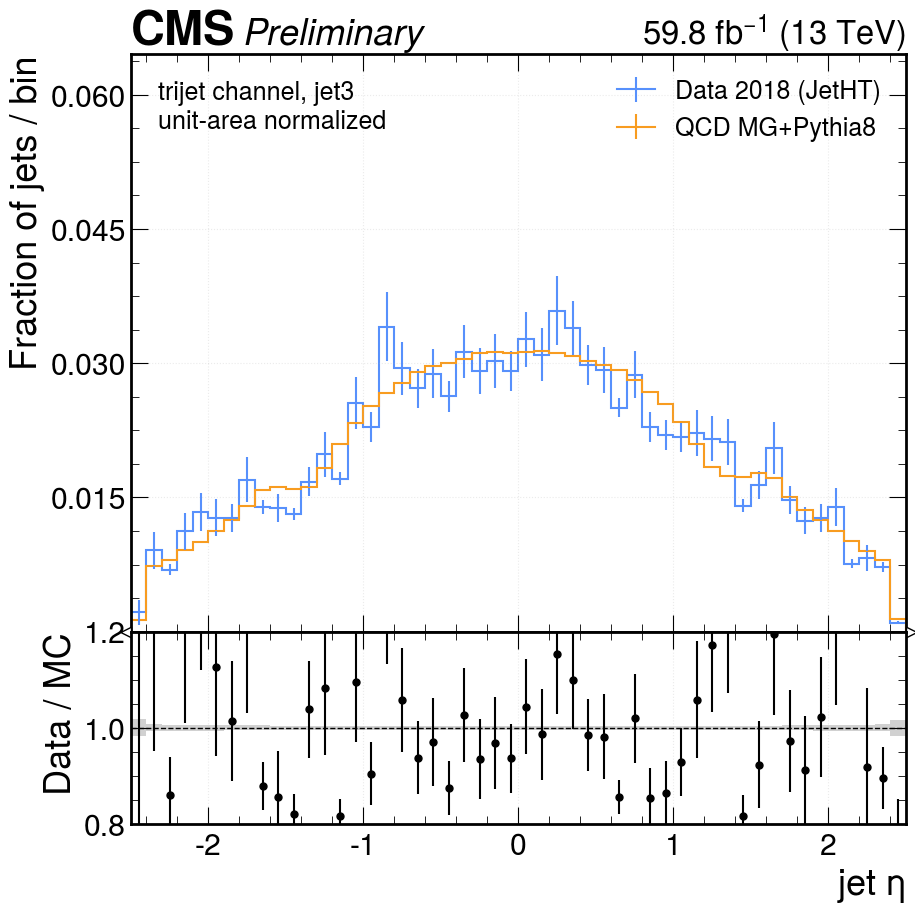

In [13]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
variable = "eta"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet3"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (-2.5, 2.5)          # x window that is drawn
ratio_y_range = (0.8, 1.2)      # y window of the Data / MC panel
log_y = False                    # log scale on the main panel
legend_headroom = 1.8      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.8** &mdash; trijet, measured-jet $\phi$ (jet 3).

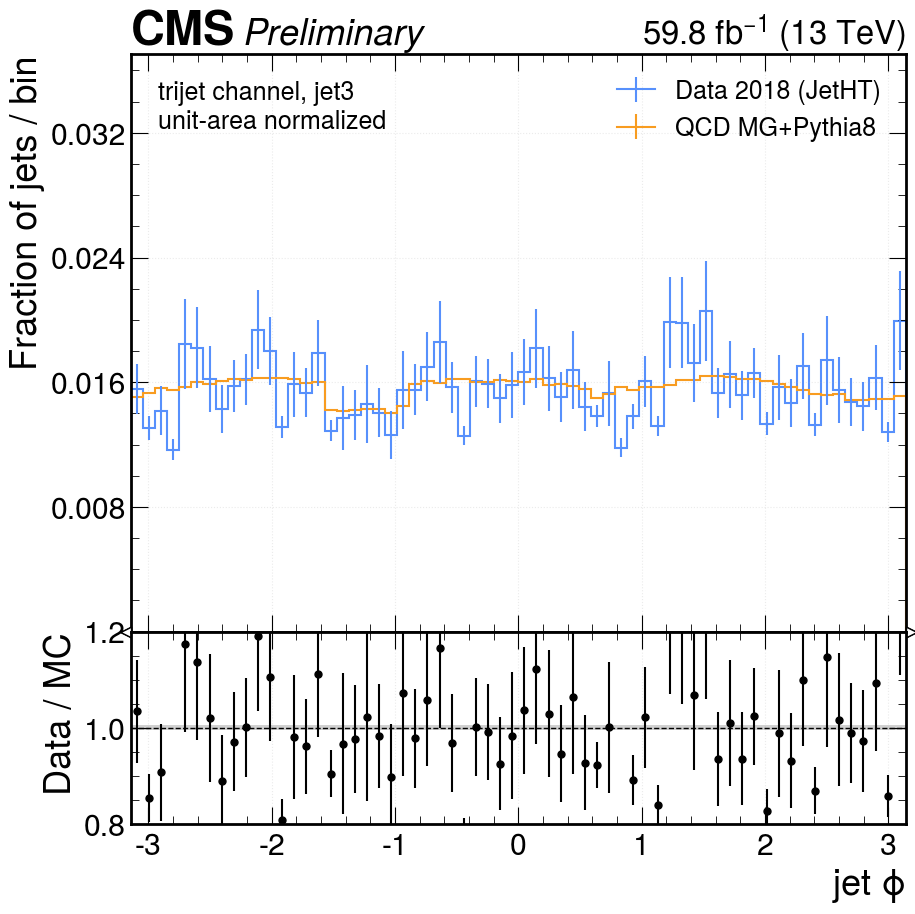

In [14]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
variable = "phi"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet3"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (-np.pi, np.pi)          # x window that is drawn
ratio_y_range = (0.8, 1.2)      # y window of the Data / MC panel
log_y = False                    # log scale on the main panel
legend_headroom = 1.8      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.9** &mdash; trijet, groomed mass $m_{\mathrm{SD}}$ (jet 3).

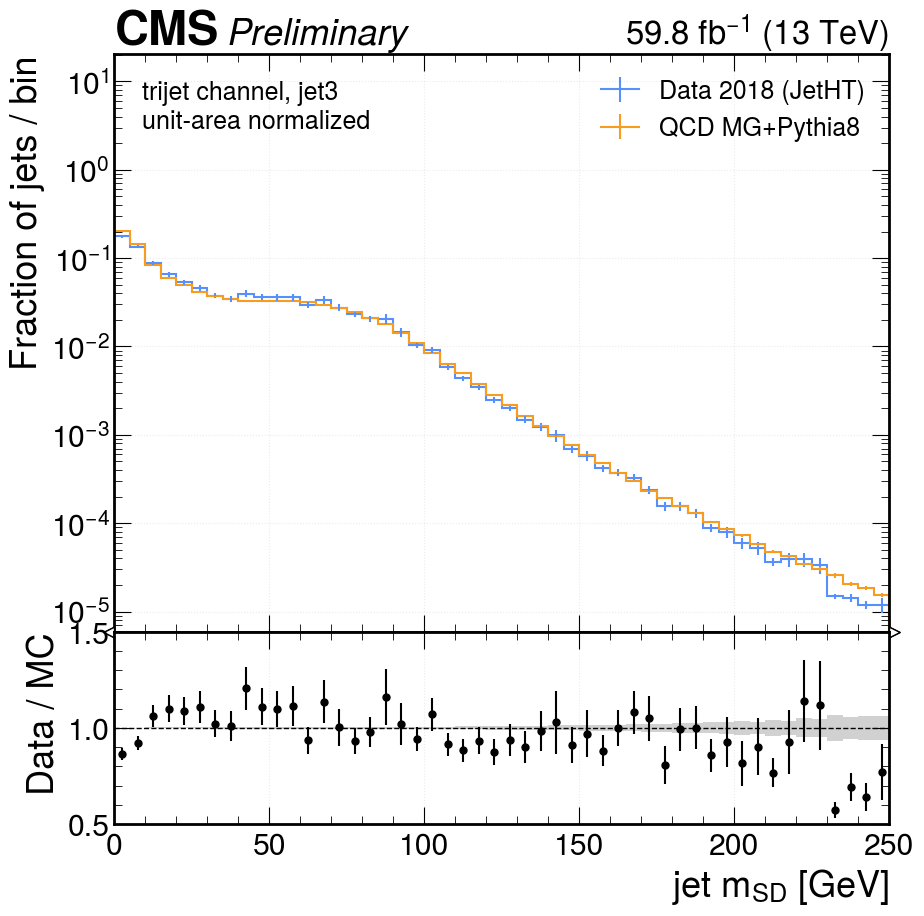

In [15]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
variable = "mass"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet3"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (0., 250.)          # x window that is drawn
ratio_y_range = (0.5, 1.5)      # y window of the Data / MC panel
log_y = True                    # log scale on the main panel
legend_headroom = 100      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 1.10** &mdash; trijet, ungroomed mass (jet 3).

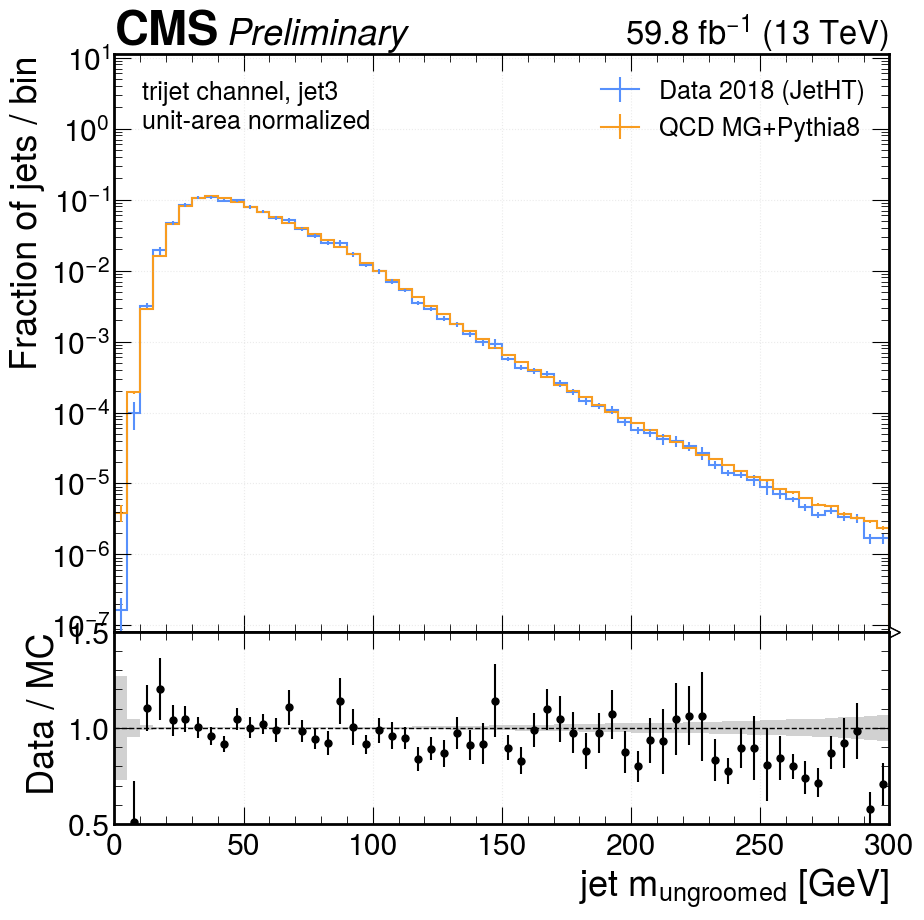

In [16]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
variable = "mass_ungroomed"
# Which measured jets go into this figure. The dijet channel measures BOTH
# leading jets; cut the list down to ["jet1"] or ["jet2"] to look at one alone.
jets_to_combine = ["jet3"]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields (also shows the overall QCD normalization)
normalization = "shape"
plot_range = (0., 300.)          # x window that is drawn
ratio_y_range = (0.5, 1.5)      # y window of the Data / MC panel
log_y = True                    # log scale on the main panel
legend_headroom = 100      # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

# hist objects add bin by bin, so summing the per-jet histograms is enough.
combined = sum(hists[f"{channel}_{jet}_{variable}"] for jet in jets_to_combine)
hist_data = combined[{"source": "data"}]
hist_mc = combined[{"source": "mc"}]
if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= plot_range[0]) & (bin_centres <= plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log" if log_y else "linear")
main_ax.set_ylim(positive.min() * 0.5 if log_y else 0.0,
                 positive.max() * legend_headroom)
if not log_y:
    # The two panels touch, so drop the main panel's LOWEST y tick label --
    # otherwise it collides with the top label of the ratio panel.
    main_ax.yaxis.set_major_locator(MaxNLocator(nbins=6, prune="lower"))
main_ax.set_ylabel("Fraction of jets / bin" if normalization == "shape"
                   else "Weighted jets / bin")
main_ax.set_xlim(*plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*plot_range)
ratio_ax.set_xlabel(AXIS_LABELS[variable])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(jets_to_combine) + "\n"
             + ("unit-area normalized" if normalization == "shape"
                else "absolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

## 2. $\log(\rho^2)$ per measured-jet $p_T$ bin, with systematics

These come from the `minimal_rho` all_syst production: the 2D histogram
`ptjet_rhojet_g_reco` (axes `ptreco` x `mpt_reco`), stored once per systematic
category. `vp.hist_variations` sums it over datasets and files and returns
`{systematic: (values, variances)}`; `vp.syst_total` symmetrizes each up/down
pair and adds the sources in quadrature.

Every figure cell slices its own $p_T$ window out of the 2D histogram with an
explicit bin-centre test, so changing `pt_bin` is enough &mdash; nothing has to
be refilled.

In [17]:
# ---- knobs -------------------------------------------------------------
cache_file = CACHE_DIR / "rho_variations.pkl"

# Name of the stored 2D histogram. `_g` = groomed; swap in
# "ptjet_rhojet_u_reco" for the ungroomed version (same systematics stored).
rho_hist_name = "ptjet_rhojet_g_reco"
# ------------------------------------------------------------------------

if cache_file.exists() and not FORCE_RECOMPUTE:
    rho_variations, rho_pt_edges, rho_axis_edges = pickle.load(open(cache_file, "rb"))
    print("loaded", cache_file.name)
else:
    rho_variations = {}
    rho_pt_edges = rho_axis_edges = None
    for channel in ("dijet", "trijet"):
        for source in ("mc", "data"):
            print(f"loading {channel} {source} {rho_hist_name} ...")
            axes, per_systematic = vp.hist_variations(
                "min", channel, source, rho_hist_name, quiet=True)
            rho_variations[(channel, source)] = per_systematic
            rho_pt_edges, rho_axis_edges = axes[0].edges, axes[1].edges
    pickle.dump((rho_variations, rho_pt_edges, rho_axis_edges),
                open(cache_file, "wb"))
    print("wrote", cache_file.name)

print("ptreco edges:", rho_pt_edges)
print("rho edges   :", rho_axis_edges)
for key, per_systematic in rho_variations.items():
    print(f"  {str(key):<20s} {len(per_systematic):3d} systematic categories, "
          f"nominal sum = {per_systematic['nominal'][0].sum():.5g}")

loaded rho_variations.pkl
ptreco edges: [  185.   200.   290.   400.   480.   570.   680.   760.   820. 13000.]
rho edges   : [-10.     -7.5    -5.     -4.5    -4.     -3.7    -3.4    -3.125  -2.85
  -2.55   -2.25   -2.025  -1.8    -1.65   -1.5    -1.4    -1.3    -1.2
  -1.1    -1.     -0.9    -0.825  -0.75   -0.7    -0.65   -0.6    -0.55
  -0.275   0.   ]
  ('dijet', 'mc')       77 systematic categories, nominal sum = 3.9218e+09
  ('dijet', 'data')      1 systematic categories, nominal sum = 4.2692e+09
  ('trijet', 'mc')      77 systematic categories, nominal sum = 2.3482e+07
  ('trijet', 'data')     1 systematic categories, nominal sum = 2.4241e+07


**Fig 2.1** &mdash; dijet, $200 < p_T^{\mathrm{jet}} < 290$ GeV.

pt rows [1]  ->  200 - 290 GeV
band in the drawn window: median 4.36%, max 14.96%
largest systematic sources (mean relative deviation over the window):
    fsr                            4.75%
    JMS                            1.48%
    isr                            1.29%
    JES_RelativeSample             0.70%
    JES_FlavorQCD                  0.69%


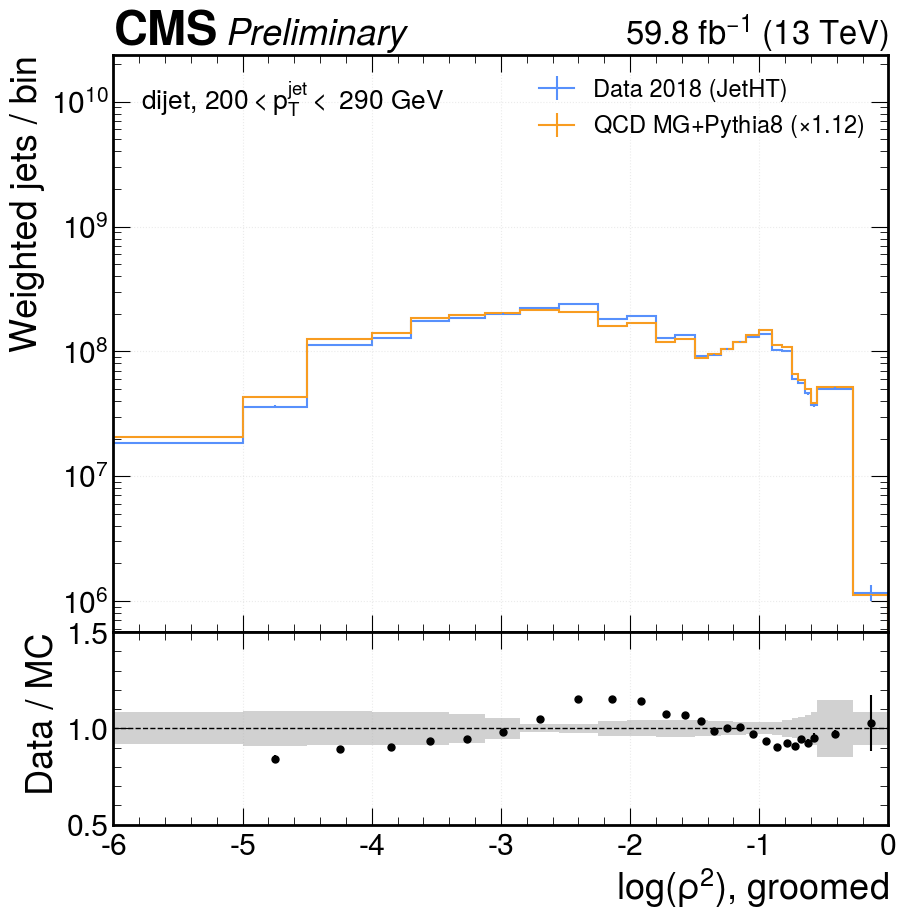

In [18]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
# Measured-jet pT window for this figure. It is matched against the BIN CENTRES
# of the stored pt axis below, so any window built from those edges works.
pt_bin = (200., 290.)
# Area-normalize MC to data INSIDE this rho window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band is renormalized
# the same way, so it follows the window too.
rho_normalization_range = (-6.0, 0.0)
rho_plot_range = (-6.0, 0.0)        # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

mc_variations = rho_variations[(channel, "mc")]
data_variations = rho_variations[(channel, "data")]

# Which rows of the 2D (ptreco x rho) histogram fall inside pt_bin. Written out
# explicitly, so widening pt_bin above simply picks up more rows.
pt_centres = 0.5 * (rho_pt_edges[1:] + rho_pt_edges[:-1])
pt_rows = np.where((pt_centres >= pt_bin[0]) & (pt_centres < pt_bin[1]))[0]
print(f"pt rows {pt_rows}  ->  {rho_pt_edges[pt_rows[0]]:.0f}"
      f" - {rho_pt_edges[pt_rows[-1] + 1]:.0f} GeV")

# Project every systematic variation onto the rho axis inside that pT window.
mc_slice = {systematic: (values[pt_rows].sum(0), variances[pt_rows].sum(0))
            for systematic, (values, variances) in mc_variations.items()}
mc_values, mc_variances = mc_slice["nominal"]
data_values = data_variations["nominal"][0][pt_rows].sum(0)
data_variances = data_variations["nominal"][1][pt_rows].sum(0)

bin_edges = rho_axis_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= rho_normalization_range[0])
                 & (bin_centres < rho_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC. (The
# RELATIVE band does not depend on what we scale to, so 1.0 is fine here.)
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_slice, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

# Put the two projections back into a named hist for plot_ratio.
hist_rho = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="rho", label=AXIS_LABELS["rho"]),
    storage=hist.storage.Weight(),
)
hist_rho[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_rho[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_rho[{"source": "data"}]
hist_mc = hist_rho[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= rho_plot_range[0]) & (bin_centres <= rho_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*rho_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*rho_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["rho"] + ", groomed")
ratio_ax.grid(alpha=0.25)
upper_label = r"$\infty$" if not np.isfinite(pt_bin[1]) else f"{pt_bin[1]:.0f}"
main_ax.text(0.035, 0.955,
             f"{channel}, ${pt_bin[0]:.0f} < p_T^{{jet}} <$ " + upper_label + " GeV",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=19)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

**Fig 2.2** &mdash; dijet, $480 < p_T^{\mathrm{jet}} < 570$ GeV.

pt rows [4]  ->  480 - 570 GeV


band in the drawn window: median 3.30%, max 14.54%
largest systematic sources (mean relative deviation over the window):
    fsr                            3.53%
    isr                            1.53%
    JMS                            1.47%
    Q2muF                          0.45%
    JES_RelativeSample             0.44%


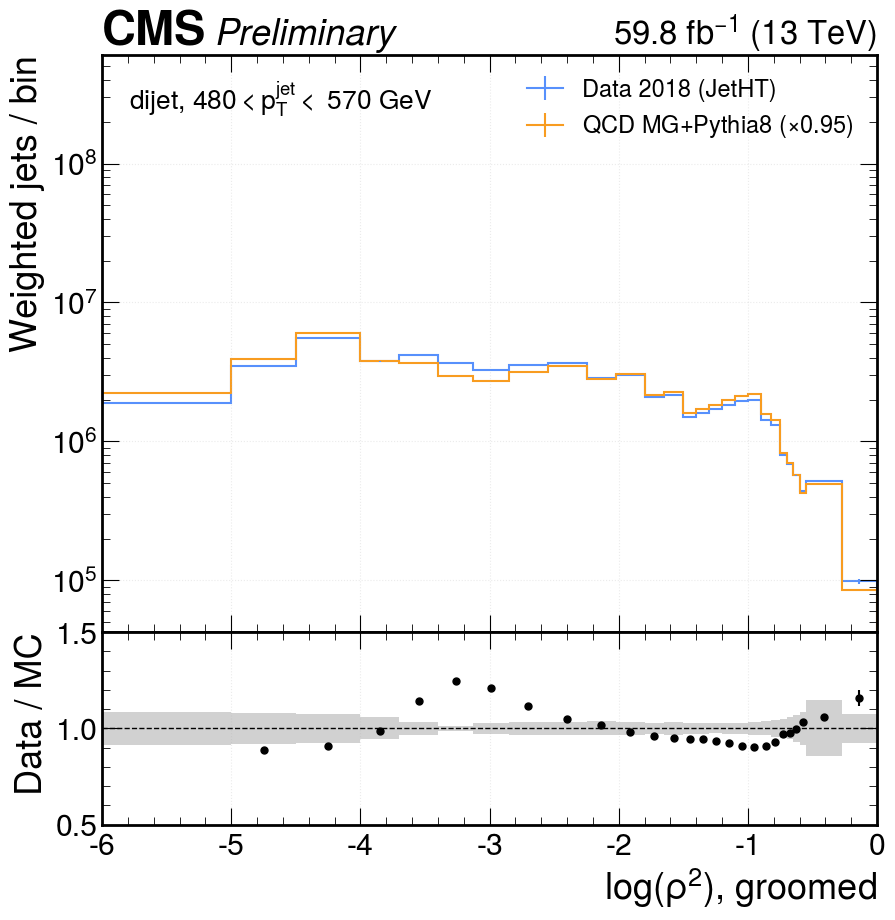

In [19]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
# Measured-jet pT window for this figure. It is matched against the BIN CENTRES
# of the stored pt axis below, so any window built from those edges works.
pt_bin = (480., 570.)
# Area-normalize MC to data INSIDE this rho window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band is renormalized
# the same way, so it follows the window too.
rho_normalization_range = (-6.0, 0.0)
rho_plot_range = (-6.0, 0.0)        # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

mc_variations = rho_variations[(channel, "mc")]
data_variations = rho_variations[(channel, "data")]

# Which rows of the 2D (ptreco x rho) histogram fall inside pt_bin. Written out
# explicitly, so widening pt_bin above simply picks up more rows.
pt_centres = 0.5 * (rho_pt_edges[1:] + rho_pt_edges[:-1])
pt_rows = np.where((pt_centres >= pt_bin[0]) & (pt_centres < pt_bin[1]))[0]
print(f"pt rows {pt_rows}  ->  {rho_pt_edges[pt_rows[0]]:.0f}"
      f" - {rho_pt_edges[pt_rows[-1] + 1]:.0f} GeV")

# Project every systematic variation onto the rho axis inside that pT window.
mc_slice = {systematic: (values[pt_rows].sum(0), variances[pt_rows].sum(0))
            for systematic, (values, variances) in mc_variations.items()}
mc_values, mc_variances = mc_slice["nominal"]
data_values = data_variations["nominal"][0][pt_rows].sum(0)
data_variances = data_variations["nominal"][1][pt_rows].sum(0)

bin_edges = rho_axis_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= rho_normalization_range[0])
                 & (bin_centres < rho_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC. (The
# RELATIVE band does not depend on what we scale to, so 1.0 is fine here.)
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_slice, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

# Put the two projections back into a named hist for plot_ratio.
hist_rho = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="rho", label=AXIS_LABELS["rho"]),
    storage=hist.storage.Weight(),
)
hist_rho[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_rho[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_rho[{"source": "data"}]
hist_mc = hist_rho[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= rho_plot_range[0]) & (bin_centres <= rho_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*rho_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*rho_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["rho"] + ", groomed")
ratio_ax.grid(alpha=0.25)
upper_label = r"$\infty$" if not np.isfinite(pt_bin[1]) else f"{pt_bin[1]:.0f}"
main_ax.text(0.035, 0.955,
             f"{channel}, ${pt_bin[0]:.0f} < p_T^{{jet}} <$ " + upper_label + " GeV",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=19)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

**Fig 2.3** &mdash; dijet, $p_T^{\mathrm{jet}} > 820$ GeV.

pt rows [8]  ->  820 - 13000 GeV
band in the drawn window: median 2.60%, max 13.23%
largest systematic sources (mean relative deviation over the window):
    fsr                            2.38%
    isr                            1.54%
    JMS                            1.50%
    Q2muF                          0.40%
    JES_RelativeSample             0.36%


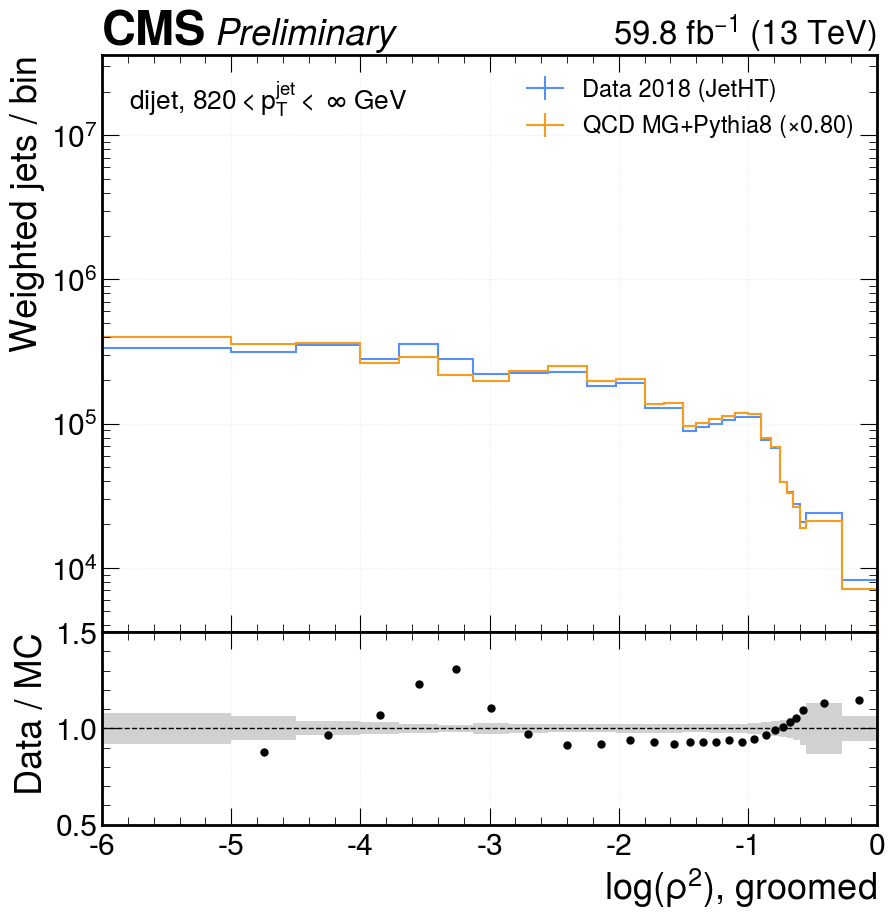

In [20]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
# Measured-jet pT window for this figure. It is matched against the BIN CENTRES
# of the stored pt axis below, so any window built from those edges works.
pt_bin = (820., np.inf)
# Area-normalize MC to data INSIDE this rho window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band is renormalized
# the same way, so it follows the window too.
rho_normalization_range = (-6.0, 0.0)
rho_plot_range = (-6.0, 0.0)        # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

mc_variations = rho_variations[(channel, "mc")]
data_variations = rho_variations[(channel, "data")]

# Which rows of the 2D (ptreco x rho) histogram fall inside pt_bin. Written out
# explicitly, so widening pt_bin above simply picks up more rows.
pt_centres = 0.5 * (rho_pt_edges[1:] + rho_pt_edges[:-1])
pt_rows = np.where((pt_centres >= pt_bin[0]) & (pt_centres < pt_bin[1]))[0]
print(f"pt rows {pt_rows}  ->  {rho_pt_edges[pt_rows[0]]:.0f}"
      f" - {rho_pt_edges[pt_rows[-1] + 1]:.0f} GeV")

# Project every systematic variation onto the rho axis inside that pT window.
mc_slice = {systematic: (values[pt_rows].sum(0), variances[pt_rows].sum(0))
            for systematic, (values, variances) in mc_variations.items()}
mc_values, mc_variances = mc_slice["nominal"]
data_values = data_variations["nominal"][0][pt_rows].sum(0)
data_variances = data_variations["nominal"][1][pt_rows].sum(0)

bin_edges = rho_axis_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= rho_normalization_range[0])
                 & (bin_centres < rho_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC. (The
# RELATIVE band does not depend on what we scale to, so 1.0 is fine here.)
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_slice, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

# Put the two projections back into a named hist for plot_ratio.
hist_rho = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="rho", label=AXIS_LABELS["rho"]),
    storage=hist.storage.Weight(),
)
hist_rho[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_rho[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_rho[{"source": "data"}]
hist_mc = hist_rho[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= rho_plot_range[0]) & (bin_centres <= rho_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*rho_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*rho_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["rho"] + ", groomed")
ratio_ax.grid(alpha=0.25)
upper_label = r"$\infty$" if not np.isfinite(pt_bin[1]) else f"{pt_bin[1]:.0f}"
main_ax.text(0.035, 0.955,
             f"{channel}, ${pt_bin[0]:.0f} < p_T^{{jet}} <$ " + upper_label + " GeV",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=19)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

**Fig 2.4** &mdash; trijet, $200 < p_T^{\mathrm{jet}} < 290$ GeV.

pt rows [1]  ->  200 - 290 GeV


band in the drawn window: median 4.78%, max 24.88%
largest systematic sources (mean relative deviation over the window):
    fsr                            5.20%
    JMS                            1.79%
    isr                            0.90%
    JES_RelativeSample             0.86%
    JES_FlavorQCD                  0.84%


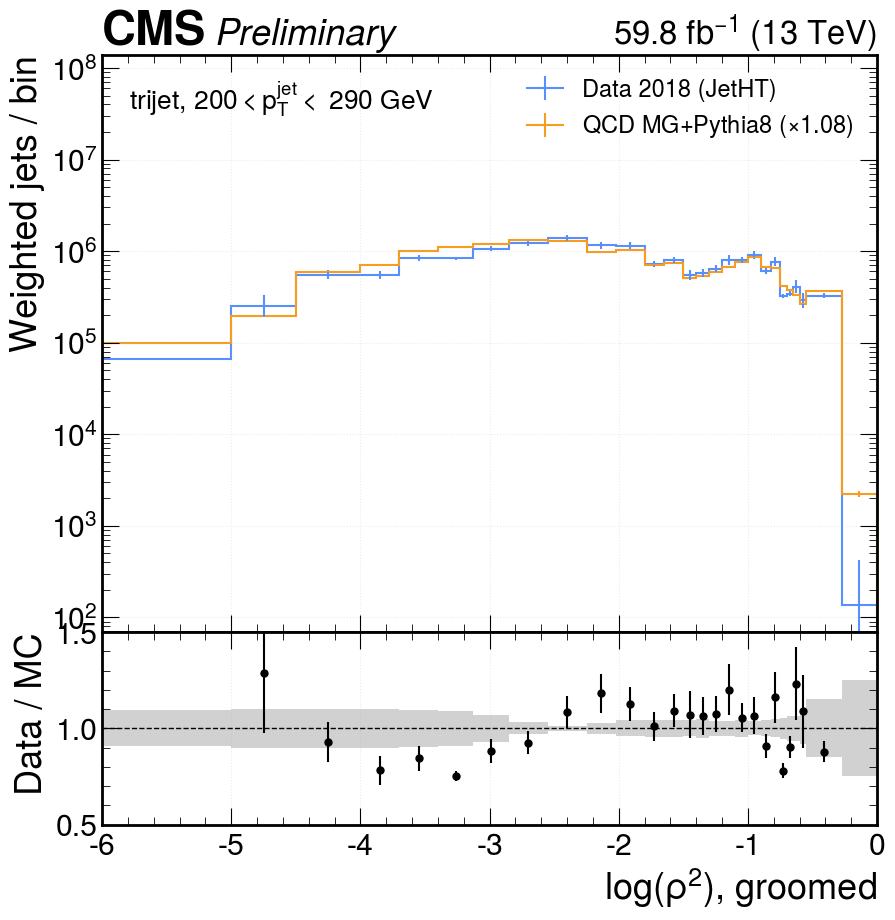

In [21]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
# Measured-jet pT window for this figure. It is matched against the BIN CENTRES
# of the stored pt axis below, so any window built from those edges works.
pt_bin = (200., 290.)
# Area-normalize MC to data INSIDE this rho window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band is renormalized
# the same way, so it follows the window too.
rho_normalization_range = (-6.0, 0.0)
rho_plot_range = (-6.0, 0.0)        # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

mc_variations = rho_variations[(channel, "mc")]
data_variations = rho_variations[(channel, "data")]

# Which rows of the 2D (ptreco x rho) histogram fall inside pt_bin. Written out
# explicitly, so widening pt_bin above simply picks up more rows.
pt_centres = 0.5 * (rho_pt_edges[1:] + rho_pt_edges[:-1])
pt_rows = np.where((pt_centres >= pt_bin[0]) & (pt_centres < pt_bin[1]))[0]
print(f"pt rows {pt_rows}  ->  {rho_pt_edges[pt_rows[0]]:.0f}"
      f" - {rho_pt_edges[pt_rows[-1] + 1]:.0f} GeV")

# Project every systematic variation onto the rho axis inside that pT window.
mc_slice = {systematic: (values[pt_rows].sum(0), variances[pt_rows].sum(0))
            for systematic, (values, variances) in mc_variations.items()}
mc_values, mc_variances = mc_slice["nominal"]
data_values = data_variations["nominal"][0][pt_rows].sum(0)
data_variances = data_variations["nominal"][1][pt_rows].sum(0)

bin_edges = rho_axis_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= rho_normalization_range[0])
                 & (bin_centres < rho_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC. (The
# RELATIVE band does not depend on what we scale to, so 1.0 is fine here.)
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_slice, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

# Put the two projections back into a named hist for plot_ratio.
hist_rho = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="rho", label=AXIS_LABELS["rho"]),
    storage=hist.storage.Weight(),
)
hist_rho[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_rho[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_rho[{"source": "data"}]
hist_mc = hist_rho[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= rho_plot_range[0]) & (bin_centres <= rho_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*rho_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*rho_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["rho"] + ", groomed")
ratio_ax.grid(alpha=0.25)
upper_label = r"$\infty$" if not np.isfinite(pt_bin[1]) else f"{pt_bin[1]:.0f}"
main_ax.text(0.035, 0.955,
             f"{channel}, ${pt_bin[0]:.0f} < p_T^{{jet}} <$ " + upper_label + " GeV",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=19)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

**Fig 2.5** &mdash; trijet, $290 < p_T^{\mathrm{jet}} < 400$ GeV.

pt rows [2]  ->  290 - 400 GeV
band in the drawn window: median 4.52%, max 16.01%
largest systematic sources (mean relative deviation over the window):
    fsr                            4.83%
    JMS                            1.58%
    isr                            1.04%
    JES_RelativeSample             0.64%
    JES_FlavorQCD                  0.59%


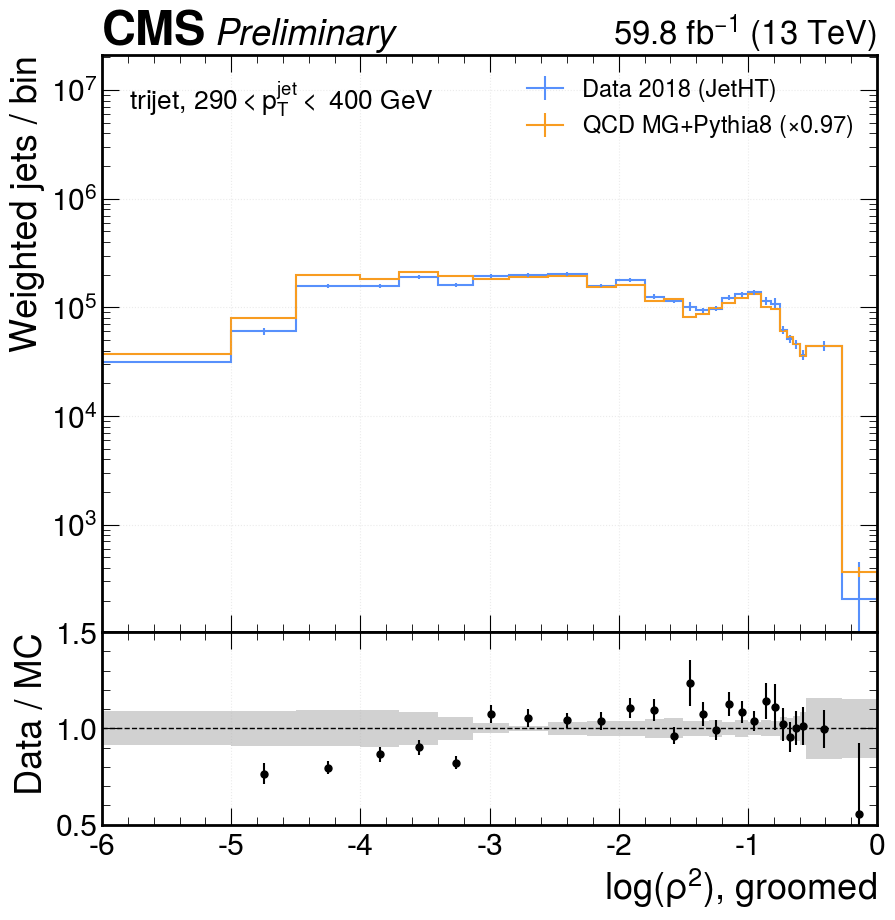

In [22]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
# Measured-jet pT window for this figure. It is matched against the BIN CENTRES
# of the stored pt axis below, so any window built from those edges works.
pt_bin = (290., 400.)
# Area-normalize MC to data INSIDE this rho window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band is renormalized
# the same way, so it follows the window too.
rho_normalization_range = (-6.0, 0.0)
rho_plot_range = (-6.0, 0.0)        # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

mc_variations = rho_variations[(channel, "mc")]
data_variations = rho_variations[(channel, "data")]

# Which rows of the 2D (ptreco x rho) histogram fall inside pt_bin. Written out
# explicitly, so widening pt_bin above simply picks up more rows.
pt_centres = 0.5 * (rho_pt_edges[1:] + rho_pt_edges[:-1])
pt_rows = np.where((pt_centres >= pt_bin[0]) & (pt_centres < pt_bin[1]))[0]
print(f"pt rows {pt_rows}  ->  {rho_pt_edges[pt_rows[0]]:.0f}"
      f" - {rho_pt_edges[pt_rows[-1] + 1]:.0f} GeV")

# Project every systematic variation onto the rho axis inside that pT window.
mc_slice = {systematic: (values[pt_rows].sum(0), variances[pt_rows].sum(0))
            for systematic, (values, variances) in mc_variations.items()}
mc_values, mc_variances = mc_slice["nominal"]
data_values = data_variations["nominal"][0][pt_rows].sum(0)
data_variances = data_variations["nominal"][1][pt_rows].sum(0)

bin_edges = rho_axis_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= rho_normalization_range[0])
                 & (bin_centres < rho_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC. (The
# RELATIVE band does not depend on what we scale to, so 1.0 is fine here.)
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_slice, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

# Put the two projections back into a named hist for plot_ratio.
hist_rho = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="rho", label=AXIS_LABELS["rho"]),
    storage=hist.storage.Weight(),
)
hist_rho[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_rho[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_rho[{"source": "data"}]
hist_mc = hist_rho[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= rho_plot_range[0]) & (bin_centres <= rho_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*rho_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*rho_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["rho"] + ", groomed")
ratio_ax.grid(alpha=0.25)
upper_label = r"$\infty$" if not np.isfinite(pt_bin[1]) else f"{pt_bin[1]:.0f}"
main_ax.text(0.035, 0.955,
             f"{channel}, ${pt_bin[0]:.0f} < p_T^{{jet}} <$ " + upper_label + " GeV",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=19)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

**Fig 2.6** &mdash; trijet, $p_T^{\mathrm{jet}} > 400$ GeV.

pt rows [3 4 5 6 7 8]  ->  400 - 13000 GeV


band in the drawn window: median 4.12%, max 16.06%
largest systematic sources (mean relative deviation over the window):
    fsr                            4.35%
    JMS                            1.56%
    isr                            0.91%
    JES_FlavorQCD                  0.51%
    JES_RelativeSample             0.49%


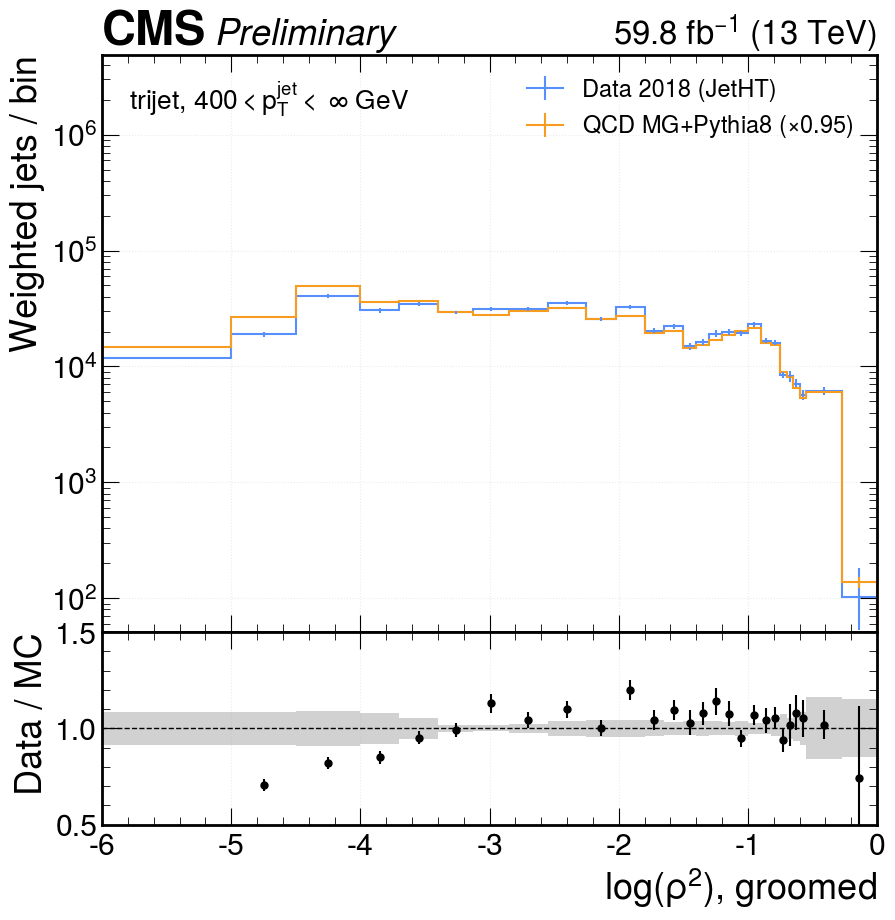

In [23]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
# Measured-jet pT window for this figure. It is matched against the BIN CENTRES
# of the stored pt axis below, so any window built from those edges works.
pt_bin = (400., np.inf)
# Area-normalize MC to data INSIDE this rho window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band is renormalized
# the same way, so it follows the window too.
rho_normalization_range = (-6.0, 0.0)
rho_plot_range = (-6.0, 0.0)        # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

mc_variations = rho_variations[(channel, "mc")]
data_variations = rho_variations[(channel, "data")]

# Which rows of the 2D (ptreco x rho) histogram fall inside pt_bin. Written out
# explicitly, so widening pt_bin above simply picks up more rows.
pt_centres = 0.5 * (rho_pt_edges[1:] + rho_pt_edges[:-1])
pt_rows = np.where((pt_centres >= pt_bin[0]) & (pt_centres < pt_bin[1]))[0]
print(f"pt rows {pt_rows}  ->  {rho_pt_edges[pt_rows[0]]:.0f}"
      f" - {rho_pt_edges[pt_rows[-1] + 1]:.0f} GeV")

# Project every systematic variation onto the rho axis inside that pT window.
mc_slice = {systematic: (values[pt_rows].sum(0), variances[pt_rows].sum(0))
            for systematic, (values, variances) in mc_variations.items()}
mc_values, mc_variances = mc_slice["nominal"]
data_values = data_variations["nominal"][0][pt_rows].sum(0)
data_variances = data_variations["nominal"][1][pt_rows].sum(0)

bin_edges = rho_axis_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= rho_normalization_range[0])
                 & (bin_centres < rho_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC. (The
# RELATIVE band does not depend on what we scale to, so 1.0 is fine here.)
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_slice, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

# Put the two projections back into a named hist for plot_ratio.
hist_rho = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="rho", label=AXIS_LABELS["rho"]),
    storage=hist.storage.Weight(),
)
hist_rho[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_rho[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_rho[{"source": "data"}]
hist_mc = hist_rho[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= rho_plot_range[0]) & (bin_centres <= rho_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*rho_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*rho_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["rho"] + ", groomed")
ratio_ax.grid(alpha=0.25)
upper_label = r"$\infty$" if not np.isfinite(pt_bin[1]) else f"{pt_bin[1]:.0f}"
main_ax.text(0.035, 0.955,
             f"{channel}, ${pt_bin[0]:.0f} < p_T^{{jet}} <$ " + upper_label + " GeV",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=19)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

## 3. $m_{\mathrm{SD}}$, $p_T$-inclusive, with systematics

`minimal_rho` stores no $p_T$-differential $m_{\mathrm{SD}}$ histogram, so this
comparison is $p_T$-inclusive. It is built from the per-jet `msoftdrop_<jet>`
histograms, summed over the measured jets of each channel (jets 1 + 2 for the
dijet channel, jet 3 for the trijet channel). The $p_T$-differential
$m_{\mathrm{SD}}$ *without* systematics is *Fig 1.4* / *Fig 1.9*.

In [24]:
# ---- knobs -------------------------------------------------------------
cache_file = CACHE_DIR / "msd_variations.pkl"

# Merge this many adjacent 5 GeV bins of the stored msoftdrop axis. 1 = native
# 5 GeV binning; 2 gives 10 GeV bins and a visibly smoother tail.
msd_rebin = 2
# ------------------------------------------------------------------------

if cache_file.exists() and not FORCE_RECOMPUTE:
    msd_variations, msd_edges = pickle.load(open(cache_file, "rb"))
    print("loaded", cache_file.name)
else:
    msd_variations, msd_edges = {}, None
    for channel, jets in JETS.items():
        for source in ("mc", "data"):
            print(f"loading {channel} {source} msoftdrop ...")
            # sum the measured jets of this channel, per systematic
            summed, fine_edges = {}, None
            for jet in jets:
                axes, per_systematic = vp.hist_variations(
                    "min", channel, source, f"msoftdrop_{jet}", quiet=True)
                fine_edges = axes[0].edges
                for systematic, (values, variances) in per_systematic.items():
                    if systematic not in summed:
                        summed[systematic] = [np.zeros_like(values),
                                              np.zeros_like(variances)]
                    summed[systematic][0] += values
                    summed[systematic][1] += variances
            # rebin: fold msd_rebin neighbouring bins into one
            keep = (len(fine_edges) - 1) // msd_rebin * msd_rebin
            msd_edges = fine_edges[:keep + 1:msd_rebin]
            msd_variations[(channel, source)] = {
                systematic: (values[:keep].reshape(-1, msd_rebin).sum(1),
                             variances[:keep].reshape(-1, msd_rebin).sum(1))
                for systematic, (values, variances) in summed.items()}
    pickle.dump((msd_variations, msd_edges), open(cache_file, "wb"))
    print("wrote", cache_file.name)

print("m_SD edges:", msd_edges[:6], "...", msd_edges[-3:])
for key, per_systematic in msd_variations.items():
    print(f"  {str(key):<20s} {len(per_systematic):3d} systematic categories, "
          f"nominal sum = {per_systematic['nominal'][0].sum():.5g}")

loaded msd_variations.pkl
m_SD edges: [ 0. 10. 20. 30. 40. 50.] ... [480. 490. 500.]
  ('dijet', 'mc')       77 systematic categories, nominal sum = 3.9342e+09
  ('dijet', 'data')      1 systematic categories, nominal sum = 4.2803e+09
  ('trijet', 'mc')      77 systematic categories, nominal sum = 2.3516e+07
  ('trijet', 'data')     1 systematic categories, nominal sum = 2.4307e+07


**Fig 3.1** &mdash; dijet, $m_{\mathrm{SD}}$ of jets 1 + 2, $p_T$-inclusive, with the full systematic envelope.

band in the drawn window: median 6.27%, max 9.12%
largest systematic sources (mean relative deviation over the window):
    fsr                            3.42%
    JMS                            3.00%
    isr                            2.81%
    Q2muF                          1.56%
    JES_RelativeSample             0.81%


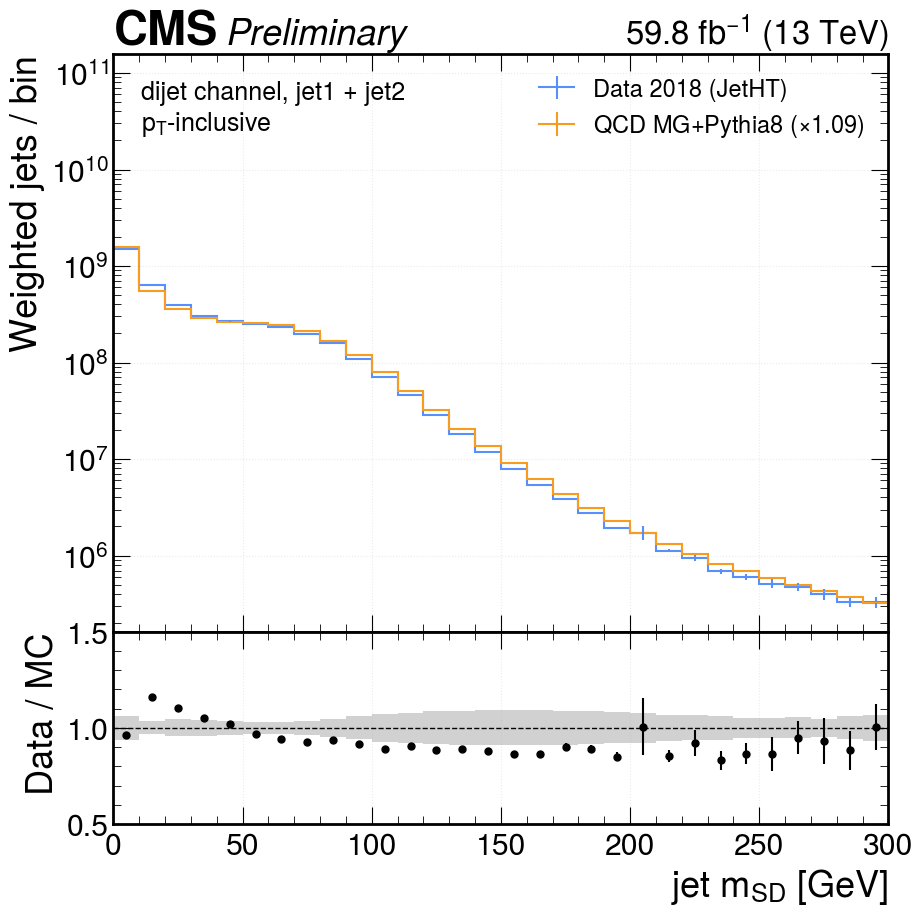

In [25]:
# ---- knobs for this figure ---------------------------------------------
channel = "dijet"
msd_plot_range = (0., 300.)         # x window that is drawn
# Area-normalize MC to data INSIDE this m_SD window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band follows.
msd_normalization_range = (0., 300.)
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# (the bin WIDTH is `msd_rebin` in the loading cell just above)
# ------------------------------------------------------------------------

mc_variations = msd_variations[(channel, "mc")]
data_variations = msd_variations[(channel, "data")]
mc_values, mc_variances = mc_variations["nominal"]
data_values, data_variances = data_variations["nominal"]

bin_edges = msd_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= msd_normalization_range[0])
                 & (bin_centres < msd_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC.
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_variations, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

hist_msd = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="mass", label=AXIS_LABELS["mass"]),
    storage=hist.storage.Weight(),
)
hist_msd[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_msd[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_msd[{"source": "data"}]
hist_mc = hist_msd[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= msd_plot_range[0]) & (bin_centres <= msd_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*msd_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*msd_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["mass"])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(JETS[channel])
             + "\n$p_T$-inclusive",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

**Fig 3.2** &mdash; trijet, $m_{\mathrm{SD}}$ of jet 3, $p_T$-inclusive, with the full systematic envelope.

band in the drawn window: median 10.40%, max 35.38%
largest systematic sources (mean relative deviation over the window):
    fsr                            5.09%
    JMS                            4.70%
    JES_RelativeSample             3.15%
    JES_FlavorQCD                  2.25%
    isr                            1.98%


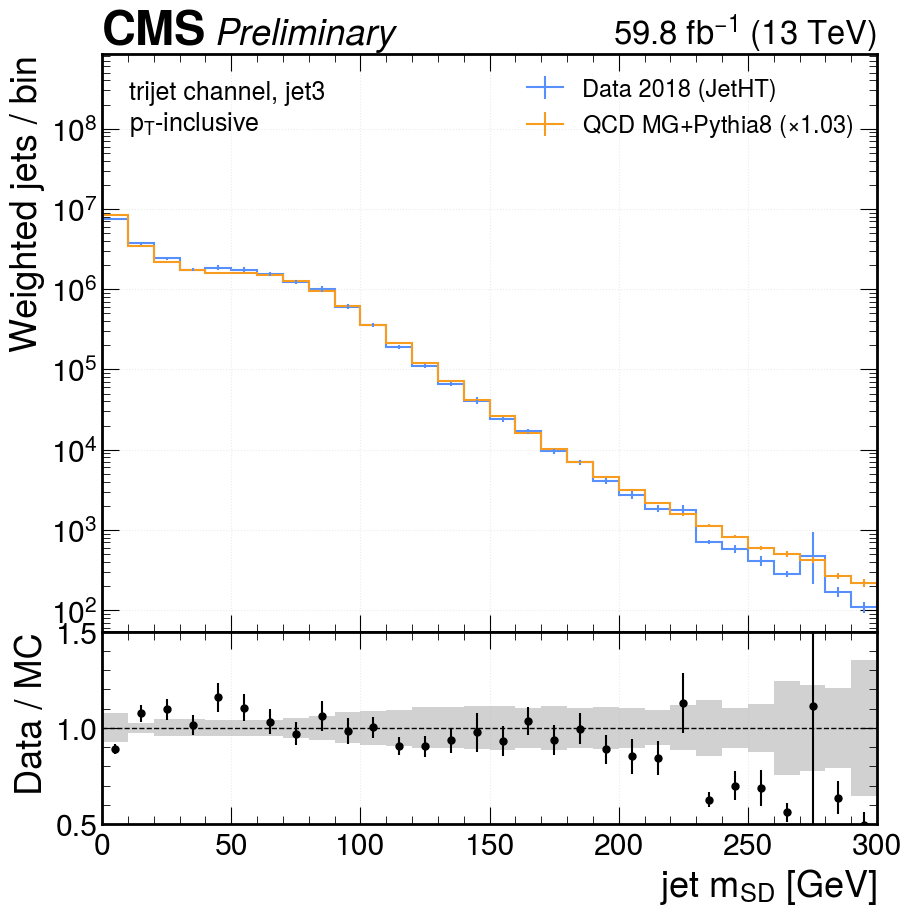

In [26]:
# ---- knobs for this figure ---------------------------------------------
channel = "trijet"
msd_plot_range = (0., 300.)         # x window that is drawn
# Area-normalize MC to data INSIDE this m_SD window only. Widen/narrow it to
# change which part of the shape sets the scale; the grey band follows.
msd_normalization_range = (0., 300.)
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# (the bin WIDTH is `msd_rebin` in the loading cell just above)
# ------------------------------------------------------------------------

mc_variations = msd_variations[(channel, "mc")]
data_variations = msd_variations[(channel, "data")]
mc_values, mc_variances = mc_variations["nominal"]
data_values, data_variances = data_variations["nominal"]

bin_edges = msd_edges
bin_centres = 0.5 * (bin_edges[1:] + bin_edges[:-1])
inside_window = ((bin_centres >= msd_normalization_range[0])
                 & (bin_centres < msd_normalization_range[1]))
mc_scale_factor = data_values[inside_window].sum() / mc_values[inside_window].sum()
mc_values = mc_values * mc_scale_factor
mc_variances = mc_variances * mc_scale_factor ** 2

# Shape-only systematic band: every variation is rescaled by ITS OWN sum inside
# the same window, exactly the way the panel rescales the nominal MC.
renormalize_in_window = lambda values: values / values[inside_window].sum()
nominal_shape, syst_envelope, syst_by_source = vp.syst_total(
    mc_variations, transform=renormalize_in_window)
with np.errstate(divide="ignore", invalid="ignore"):
    relative_syst = np.where(nominal_shape > 0, syst_envelope / nominal_shape, 0.0)
    relative_stat = np.where(mc_values > 0, np.sqrt(mc_variances) / mc_values, 0.0)
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
relative_band = np.sqrt(relative_stat ** 2 + relative_syst ** 2)

hist_msd = hist.Hist(
    hist.axis.StrCategory(["mc", "data"], name="source", label="source"),
    hist.axis.Variable(bin_edges, name="mass", label=AXIS_LABELS["mass"]),
    storage=hist.storage.Weight(),
)
hist_msd[{"source": "mc"}] = np.stack([mc_values, mc_variances], axis=-1)
hist_msd[{"source": "data"}] = np.stack([data_values, data_variances], axis=-1)
hist_data = hist_msd[{"source": "data"}]
hist_mc = hist_msd[{"source": "mc"}]

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL + rf" ($\times${mc_scale_factor:.2f})",
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = stat (+) syst envelope, renormalized like the panel
ratio_ax.stairs(1 + relative_band, bin_edges, baseline=1 - relative_band,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

visible = (bin_centres >= msd_plot_range[0]) & (bin_centres <= msd_plot_range[1])
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Weighted jets / bin")
main_ax.set_xlim(*msd_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=17)
ratio_ax.set_xlim(*msd_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["mass"])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             f"{channel} channel, " + " + ".join(JETS[channel])
             + "\n$p_T$-inclusive",
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)

shown = visible & (relative_band > 0)
print(f"band in the drawn window: median {100 * np.median(relative_band[shown]):.2f}%,"
      f" max {100 * relative_band[shown].max():.2f}%")
print("largest systematic sources (mean relative deviation over the window):")
for size, name in sorted(((float(np.mean(dev[shown] / nominal_shape[shown])), name)
                          for name, dev in syst_by_source.items()), reverse=True)[:5]:
    print(f"    {name:<28s} {100 * size:6.2f}%")
plt.show()

## 4. Boundary distance $D$ of the leading dijet pair

The pair_split selection cuts one variable on the two leading AK8 jets,

$$D \;=\; \Delta\phi_{12} \;-\; \Big(\pi - \frac{200\ \mathrm{GeV}}{\bar p_T}\Big),
\qquad \bar p_T = \tfrac{1}{2}\,(p_{T,1} + p_{T,2}),$$

with $D > 0$ for the dijet channel and $D < 0$ for the trijet channel. Every
selected dijet pair must therefore have $D > 0$ &mdash; the fill cell checks
that &mdash; and the shape of $D$ near zero is where a data/MC mismodelling of
the boundary would show up.

In [27]:
# ---- knobs -------------------------------------------------------------
cache_file = CACHE_DIR / "boundary_hists.pkl"

# Leading-jet pT windows used by the figures below. Any window built from
# PT_EDGES["dijet"] works and needs NO refill -- the histogram is filled with
# the full analysis pT axis and each figure slices it.
boundary_pt1_bins = [(200., 290.), (400., 570.), (760., np.inf)]

PT_SPLIT = 200.    # GeV, the numerator of the dphi boundary
# ------------------------------------------------------------------------

if cache_file.exists() and not FORCE_RECOMPUTE:
    hist_boundary, hists["dijet_pair_D"] = pickle.load(open(cache_file, "rb"))
    print("loaded", cache_file.name)
else:
    # source x leading-jet pT x D. The D binning is BIN_EDGES["D"] from the
    # binning cell; the pT binning is the analysis one.
    hist_boundary = hist.Hist(
        hist.axis.StrCategory([], growth=True, name="source", label="source"),
        hist.axis.Variable(PT_EDGES["dijet"], name="pt1",
                           label=r"leading jet $p_T$ [GeV]"),
        hist.axis.Variable(BIN_EDGES["D"], name="D", label=AXIS_LABELS["D"]),
        storage=hist.storage.Weight(),
    )
    hists["dijet_pair_D"] = make_hist("D")

    for source in ("mc", "data"):
        n_negative = n_total = 0
        print(f"filling dijet {source} pairs ...")
        for _, table in vp.stream_table(
                "new", "dijet", source, "reco",
                ("ptreco", "phireco", "jetidx", "weight"), quiet=True):
            # The two measured jets of an event sit on consecutive rows,
            # jetidx 0 then jetidx 1. Assert that rather than assume it.
            jet_index = table["jetidx"]
            assert np.all(jet_index[0::2] == 0) and np.all(jet_index[1::2] == 1), \
                "dijet reco table is not the expected alternating 0, 1 layout"
            leading_pt, partner_pt = table["ptreco"][0::2], table["ptreco"][1::2]
            leading_phi, partner_phi = table["phireco"][0::2], table["phireco"][1::2]
            pair_weight = table["weight"][0::2]   # both rows carry the same weight

            # |dphi| folded into [0, pi]
            delta_phi = np.abs(leading_phi - partner_phi)
            delta_phi = np.where(delta_phi > np.pi, 2 * np.pi - delta_phi, delta_phi)
            # distance to the boundary dphi12 = pi - 200 GeV / ptavg
            pt_average = 0.5 * (leading_pt + partner_pt)
            boundary_distance = delta_phi - (np.pi - PT_SPLIT / pt_average)

            hist_boundary.fill(source, leading_pt, boundary_distance,
                               weight=pair_weight)
            hists["dijet_pair_D"].fill(source, boundary_distance,
                                       weight=pair_weight)
            n_negative += int((boundary_distance < 0).sum())
            n_total += len(boundary_distance)
        print(f"  closure: {n_negative} of {n_total} selected dijet pairs have "
              f"D < 0  ({'PASS' if n_negative == 0 else 'FAIL'})")

    pickle.dump((hist_boundary, hists["dijet_pair_D"]), open(cache_file, "wb"))
    print("wrote", cache_file.name)

print("pT1 axis:", hist_boundary.axes["pt1"].edges)
print("D axis  :", hist_boundary.axes["D"].edges[:4], "...",
      hist_boundary.axes["D"].edges[-2:])

loaded boundary_hists.pkl
pT1 axis: [ 200.  290.  400.  480.  570.  680.  760.  820. 1500.]
D axis  : [0.    0.025 0.05  0.075] ... [1.575 1.6  ]


**Fig 4.1** &mdash; boundary distance $D$, all leading-jet $p_T$ (the scaffold's `hists[\"dijet_pair_D\"]` placeholder).

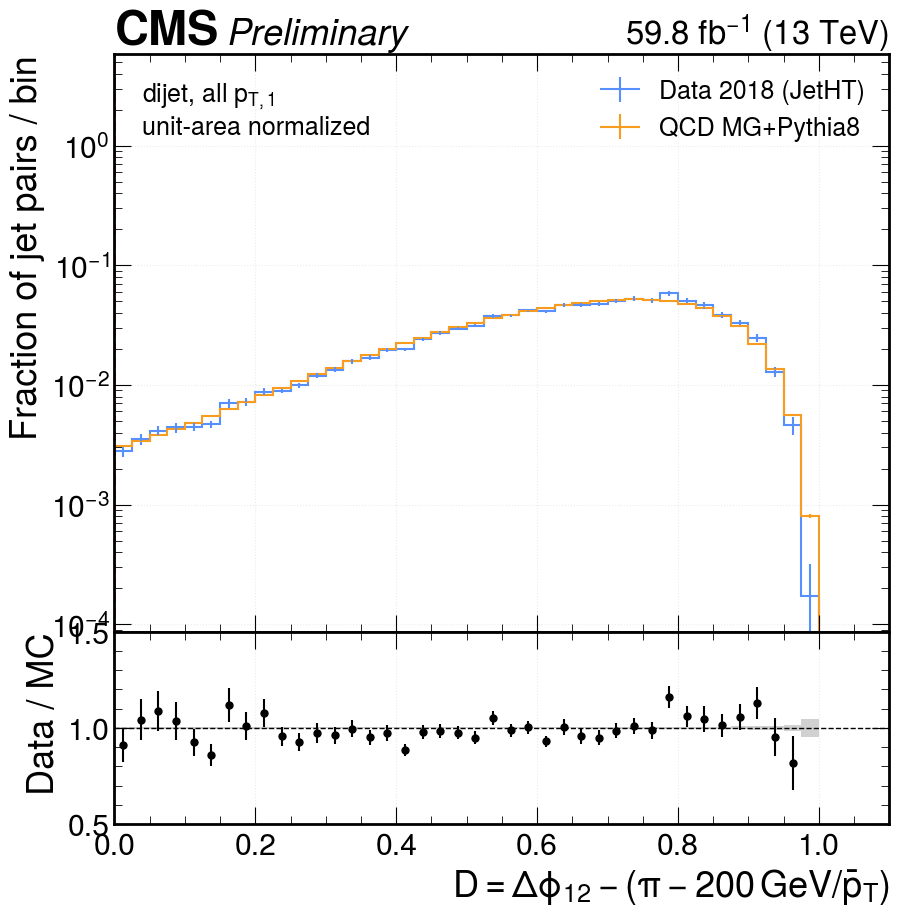

In [28]:
# ---- knobs for this figure ---------------------------------------------
# Leading-jet pT window. `None` means "no pT slicing at all".
pt1_bin = None
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields
normalization = "shape"
boundary_plot_range = (0., 1.1)     # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

if pt1_bin is None:
    # the pT-inclusive placeholder the scaffold defined
    hist_data = hists["dijet_pair_D"][{"source": "data"}]
    hist_mc = hists["dijet_pair_D"][{"source": "mc"}]
    panel_note = r"dijet, all $p_{T,1}$"
else:
    # Turn the pT window into hist bin indices explicitly: searchsorted on the
    # stored edges, clipped to the last edge so np.inf means "up to the top".
    pt1_edges = hist_boundary.axes["pt1"].edges
    first_bin = int(np.searchsorted(pt1_edges, pt1_bin[0], side="left"))
    last_bin = int(np.searchsorted(pt1_edges, min(pt1_bin[1], pt1_edges[-1]),
                                   side="left"))
    print(f"pt1 bins {first_bin}..{last_bin - 1}  ->  "
          f"{pt1_edges[first_bin]:.0f} - {pt1_edges[last_bin]:.0f} GeV")
    hist_data = hist_boundary[{"source": "data",
                               "pt1": slice(first_bin, last_bin, sum)}]
    hist_mc = hist_boundary[{"source": "mc",
                             "pt1": slice(first_bin, last_bin, sum)}]
    upper_label = r"$\infty$" if not np.isfinite(pt1_bin[1]) else f"{pt1_bin[1]:.0f}"
    panel_note = (f"dijet, ${pt1_bin[0]:.0f} < p_{{T,1}} <$ "
                  + upper_label + " GeV")

if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

# D = 0 is the selection boundary itself: everything to its left is trijet.
main_ax.axvline(0.0, color="#e42536", lw=2.0, ls="--")

visible = ((bin_centres >= boundary_plot_range[0])
           & (bin_centres <= boundary_plot_range[1]))
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Fraction of jet pairs / bin" if normalization == "shape"
                   else "Weighted jet pairs / bin")
main_ax.set_xlim(*boundary_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*boundary_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["D"])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             panel_note + ("\nunit-area normalized" if normalization == "shape"
                           else "\nabsolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 4.2** &mdash; boundary distance $D$, $200 < p_{T,1} < 290$ GeV.

pt1 bins 0..0  ->  200 - 290 GeV


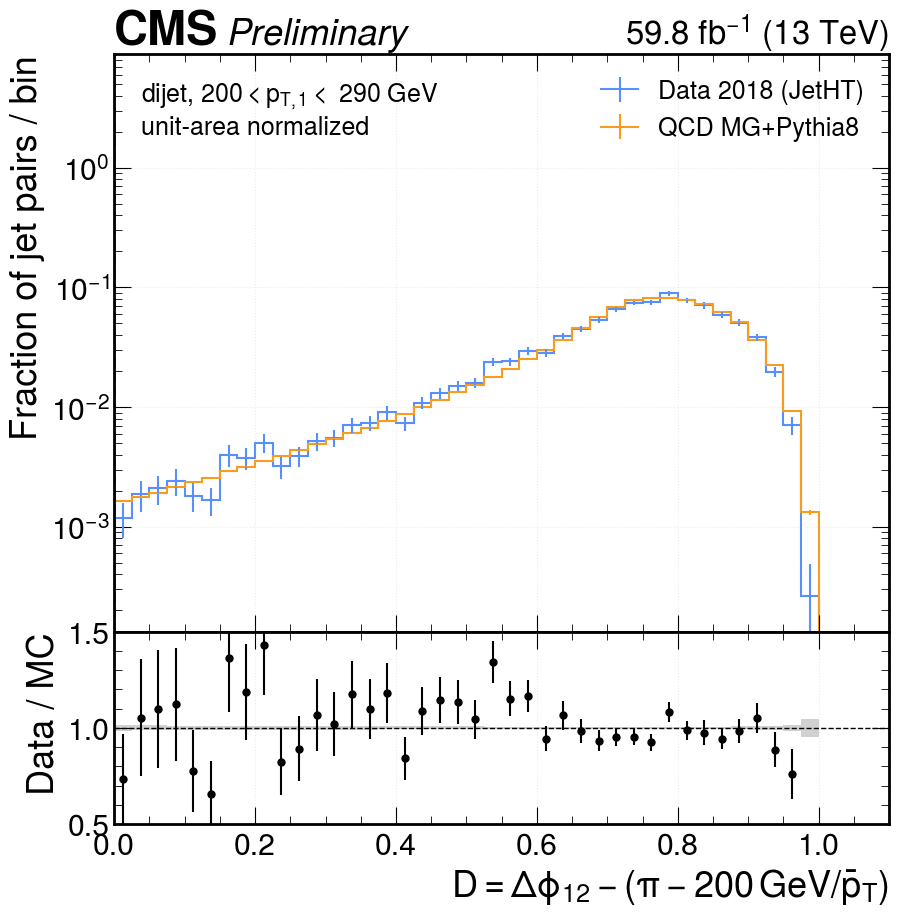

In [29]:
# ---- knobs for this figure ---------------------------------------------
# Leading-jet pT window. `None` means "no pT slicing at all".
pt1_bin = boundary_pt1_bins[0]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields
normalization = "shape"
boundary_plot_range = (0., 1.1)     # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

if pt1_bin is None:
    # the pT-inclusive placeholder the scaffold defined
    hist_data = hists["dijet_pair_D"][{"source": "data"}]
    hist_mc = hists["dijet_pair_D"][{"source": "mc"}]
    panel_note = r"dijet, all $p_{T,1}$"
else:
    # Turn the pT window into hist bin indices explicitly: searchsorted on the
    # stored edges, clipped to the last edge so np.inf means "up to the top".
    pt1_edges = hist_boundary.axes["pt1"].edges
    first_bin = int(np.searchsorted(pt1_edges, pt1_bin[0], side="left"))
    last_bin = int(np.searchsorted(pt1_edges, min(pt1_bin[1], pt1_edges[-1]),
                                   side="left"))
    print(f"pt1 bins {first_bin}..{last_bin - 1}  ->  "
          f"{pt1_edges[first_bin]:.0f} - {pt1_edges[last_bin]:.0f} GeV")
    hist_data = hist_boundary[{"source": "data",
                               "pt1": slice(first_bin, last_bin, sum)}]
    hist_mc = hist_boundary[{"source": "mc",
                             "pt1": slice(first_bin, last_bin, sum)}]
    upper_label = r"$\infty$" if not np.isfinite(pt1_bin[1]) else f"{pt1_bin[1]:.0f}"
    panel_note = (f"dijet, ${pt1_bin[0]:.0f} < p_{{T,1}} <$ "
                  + upper_label + " GeV")

if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

# D = 0 is the selection boundary itself: everything to its left is trijet.
main_ax.axvline(0.0, color="#e42536", lw=2.0, ls="--")

visible = ((bin_centres >= boundary_plot_range[0])
           & (bin_centres <= boundary_plot_range[1]))
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Fraction of jet pairs / bin" if normalization == "shape"
                   else "Weighted jet pairs / bin")
main_ax.set_xlim(*boundary_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*boundary_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["D"])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             panel_note + ("\nunit-area normalized" if normalization == "shape"
                           else "\nabsolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 4.3** &mdash; boundary distance $D$, $400 < p_{T,1} < 570$ GeV.

pt1 bins 2..3  ->  400 - 570 GeV


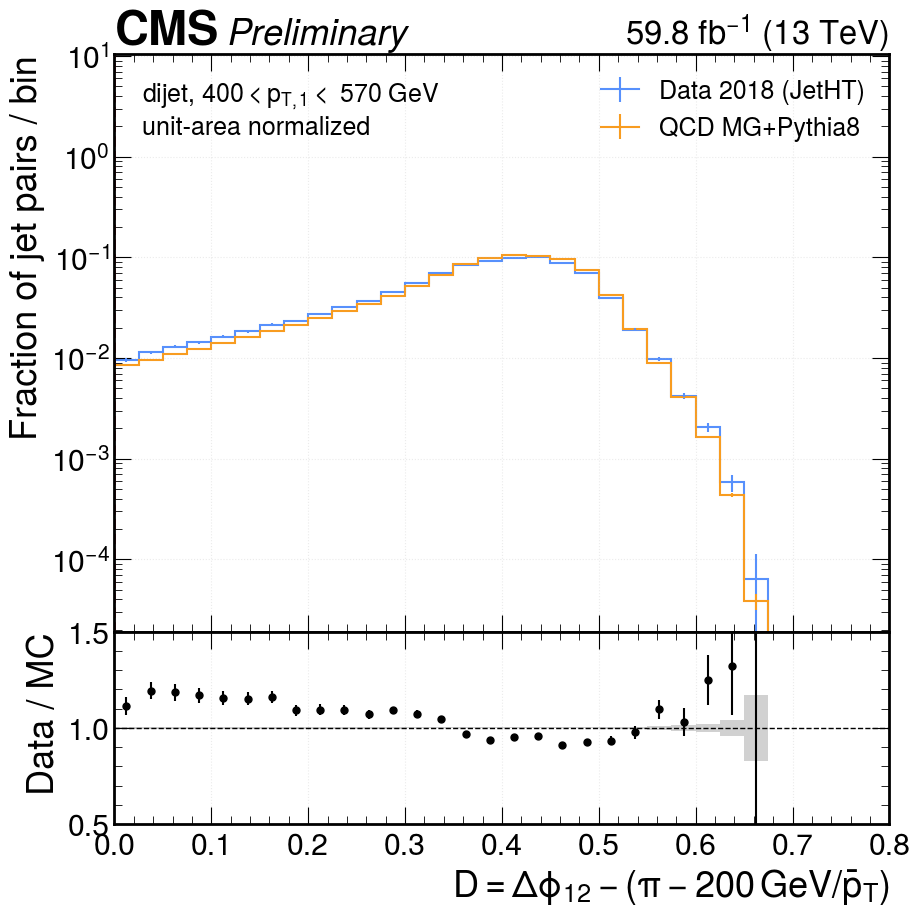

In [30]:
# ---- knobs for this figure ---------------------------------------------
# Leading-jet pT window. `None` means "no pT slicing at all".
pt1_bin = boundary_pt1_bins[1]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields
normalization = "shape"
boundary_plot_range = (0., 0.8)     # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

if pt1_bin is None:
    # the pT-inclusive placeholder the scaffold defined
    hist_data = hists["dijet_pair_D"][{"source": "data"}]
    hist_mc = hists["dijet_pair_D"][{"source": "mc"}]
    panel_note = r"dijet, all $p_{T,1}$"
else:
    # Turn the pT window into hist bin indices explicitly: searchsorted on the
    # stored edges, clipped to the last edge so np.inf means "up to the top".
    pt1_edges = hist_boundary.axes["pt1"].edges
    first_bin = int(np.searchsorted(pt1_edges, pt1_bin[0], side="left"))
    last_bin = int(np.searchsorted(pt1_edges, min(pt1_bin[1], pt1_edges[-1]),
                                   side="left"))
    print(f"pt1 bins {first_bin}..{last_bin - 1}  ->  "
          f"{pt1_edges[first_bin]:.0f} - {pt1_edges[last_bin]:.0f} GeV")
    hist_data = hist_boundary[{"source": "data",
                               "pt1": slice(first_bin, last_bin, sum)}]
    hist_mc = hist_boundary[{"source": "mc",
                             "pt1": slice(first_bin, last_bin, sum)}]
    upper_label = r"$\infty$" if not np.isfinite(pt1_bin[1]) else f"{pt1_bin[1]:.0f}"
    panel_note = (f"dijet, ${pt1_bin[0]:.0f} < p_{{T,1}} <$ "
                  + upper_label + " GeV")

if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

# D = 0 is the selection boundary itself: everything to its left is trijet.
main_ax.axvline(0.0, color="#e42536", lw=2.0, ls="--")

visible = ((bin_centres >= boundary_plot_range[0])
           & (bin_centres <= boundary_plot_range[1]))
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Fraction of jet pairs / bin" if normalization == "shape"
                   else "Weighted jet pairs / bin")
main_ax.set_xlim(*boundary_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*boundary_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["D"])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             panel_note + ("\nunit-area normalized" if normalization == "shape"
                           else "\nabsolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()

**Fig 4.4** &mdash; boundary distance $D$, $p_{T,1} > 760$ GeV.

pt1 bins 6..7  ->  760 - 1500 GeV


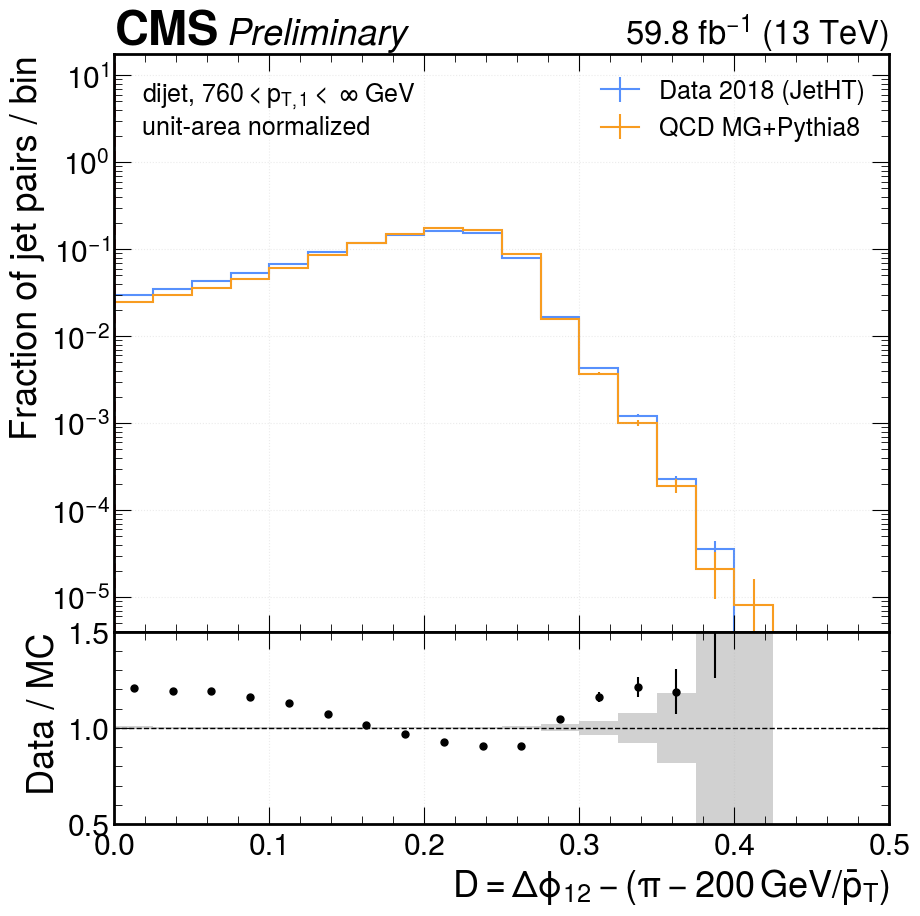

In [31]:
# ---- knobs for this figure ---------------------------------------------
# Leading-jet pT window. `None` means "no pT slicing at all".
pt1_bin = boundary_pt1_bins[2]
# "shape"    -> both curves normalized to unit area (compares SHAPES only)
# "absolute" -> raw weighted yields
normalization = "shape"
boundary_plot_range = (0., 0.5)     # x window that is drawn
ratio_y_range = (0.5, 1.5)          # y window of the Data / MC panel
legend_headroom = 1e2               # multiply the peak by this to clear the legend
# ------------------------------------------------------------------------

if pt1_bin is None:
    # the pT-inclusive placeholder the scaffold defined
    hist_data = hists["dijet_pair_D"][{"source": "data"}]
    hist_mc = hists["dijet_pair_D"][{"source": "mc"}]
    panel_note = r"dijet, all $p_{T,1}$"
else:
    # Turn the pT window into hist bin indices explicitly: searchsorted on the
    # stored edges, clipped to the last edge so np.inf means "up to the top".
    pt1_edges = hist_boundary.axes["pt1"].edges
    first_bin = int(np.searchsorted(pt1_edges, pt1_bin[0], side="left"))
    last_bin = int(np.searchsorted(pt1_edges, min(pt1_bin[1], pt1_edges[-1]),
                                   side="left"))
    print(f"pt1 bins {first_bin}..{last_bin - 1}  ->  "
          f"{pt1_edges[first_bin]:.0f} - {pt1_edges[last_bin]:.0f} GeV")
    hist_data = hist_boundary[{"source": "data",
                               "pt1": slice(first_bin, last_bin, sum)}]
    hist_mc = hist_boundary[{"source": "mc",
                             "pt1": slice(first_bin, last_bin, sum)}]
    upper_label = r"$\infty$" if not np.isfinite(pt1_bin[1]) else f"{pt1_bin[1]:.0f}"
    panel_note = (f"dijet, ${pt1_bin[0]:.0f} < p_{{T,1}} <$ "
                  + upper_label + " GeV")

if normalization == "shape":
    hist_data = hist_data * (1.0 / hist_data.values().sum())
    hist_mc = hist_mc * (1.0 / hist_mc.values().sum())

data_values, data_variances = hist_data.values(), hist_data.variances()
mc_values, mc_variances = hist_mc.values(), hist_mc.variances()
bin_edges = hist_data.axes[0].edges
bin_centres = hist_data.axes[0].centers
with np.errstate(divide="ignore", invalid="ignore"):
    data_over_mc = np.where(mc_values > 0, data_values / mc_values, np.nan)
    data_over_mc_error = np.where(mc_values > 0,
                                  np.sqrt(data_variances) / mc_values, np.nan)
    mc_relative_error = np.where(mc_values > 0,
                                 np.sqrt(mc_variances) / mc_values, 0.0)

fig = plt.figure(figsize=(10, 10))
main_artists, ratio_artists = hist_data.plot_ratio(
    hist_mc,
    rp_ylabel="Data / MC",
    rp_num_label=DATA_LABEL,
    rp_denom_label=MC_LABEL,
    rp_ylim=ratio_y_range,
)
main_ax, ratio_ax = fig.axes

# plot_ratio's ratio points assume Poisson counts and sit at the left bin edge;
# redraw them at the bin centres with the weighted data error (see the intro).
ratio_artists.errorbar.remove()
ratio_ax.errorbar(bin_centres, data_over_mc, yerr=data_over_mc_error,
                  fmt="o", ms=5, color="k")

# grey band = MC statistical uncertainty only (these skims carry no systematics)
ratio_ax.stairs(1 + mc_relative_error, bin_edges, baseline=1 - mc_relative_error,
                fill=True, color="0.6", alpha=0.45, lw=0, zorder=0)

# D = 0 is the selection boundary itself: everything to its left is trijet.
main_ax.axvline(0.0, color="#e42536", lw=2.0, ls="--")

visible = ((bin_centres >= boundary_plot_range[0])
           & (bin_centres <= boundary_plot_range[1]))
positive = np.concatenate([data_values[visible], mc_values[visible]])
positive = positive[positive > 0]
main_ax.set_yscale("log")
main_ax.set_ylim(positive.min() * 0.5, positive.max() * legend_headroom)
main_ax.set_ylabel("Fraction of jet pairs / bin" if normalization == "shape"
                   else "Weighted jet pairs / bin")
main_ax.set_xlim(*boundary_plot_range)
main_ax.grid(alpha=0.25)
main_ax.legend(loc="upper right", fontsize=18)
ratio_ax.set_xlim(*boundary_plot_range)
ratio_ax.set_xlabel(AXIS_LABELS["D"])
ratio_ax.grid(alpha=0.25)
main_ax.text(0.035, 0.955,
             panel_note + ("\nunit-area normalized" if normalization == "shape"
                           else "\nabsolute yields"),
             transform=main_ax.transAxes, ha="left", va="top", fontsize=18)
hep.cms.label("Preliminary", data=True, loc=0, ax=main_ax, rlabel=LUMI)
plt.show()